# **Step 1 : Dataset Loading & Initial Inspection**

In [ ]:
!pip install -q datasets

In [ ]:
from datasets import load_dataset

ds = load_dataset("mvasil/polyvore-outfits", "nondisjoint")

README.md:   0%|          | 0.00/6.87k [00:00<?, ?B/s]

data/nondisjoint/train.parquet: reconstructing file:   0%|          |  0.00B / 1.92GB            

data/nondisjoint/train.parquet: downloading bytes:           |  0.00B            

data/nondisjoint/validation.parquet: reconstructing file:   0%|          |  0.00B /  234MB            

data/nondisjoint/validation.parquet: downloading bytes:           |  0.00B            

data/nondisjoint/test.parquet: reconstructing file:   0%|          |  0.00B /  447MB            

data/nondisjoint/test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/204679 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25132 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/47854 [00:00<?, ? examples/s]

In [ ]:
print(ds)

DatasetDict({
    train: Dataset({
        features: ['item_id', 'image'],
        num_rows: 204679
    })
    validation: Dataset({
        features: ['item_id', 'image'],
        num_rows: 25132
    })
    test: Dataset({
        features: ['item_id', 'image'],
        num_rows: 47854
    })
})


In [ ]:
# Display the number of samples in each split

print("Dataset Summary")
print("=" * 40)

print(f"Training samples:   {len(ds['train']):,}")
print(f"Validation samples: {len(ds['validation']):,}")
print(f"Test samples:       {len(ds['test']):,}")

total = len(ds["train"]) + len(ds["validation"]) + len(ds["test"])
print(f"Total samples:      {total:,}")

Dataset Summary
Training samples:   204,679
Validation samples: 25,132
Test samples:       47,854
Total samples:      277,665


In [ ]:
print(ds["train"].features)

{'item_id': Value('string'), 'image': {'bytes': Value('binary'), 'path': Value('string')}}


In [ ]:
print(ds["train"][0])

{'item_id': '41533392', 'image': {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\x08\x06\x06\x07\x06\x05\x08\x07\x07\x07\t\t\x08\n\x0c\x14\r\x0c\x0b\x0b\x0c\x19\x12\x13\x0f\x14\x1d\x1a\x1f\x1e\x1d\x1a\x1c\x1c $.\' ",#\x1c\x1c(7),01444\x1f\'9=82<.342\xff\xdb\x00C\x01\t\t\t\x0c\x0b\x0c\x18\r\r\x182!\x1c!22222222222222222222222222222222222222222222222222\xff\xc0\x00\x11\x08\x01,\x01,\x03\x01"\x00\x02\x11\x01\x03\x11\x01\xff\xc4\x00\x1f\x00\x00\x01\x05\x01\x01\x01\x01\x01\x01\x00\x00\x00\x00\x00\x00\x00\x00\x01\x02\x03\x04\x05\x06\x07\x08\t\n\x0b\xff\xc4\x00\xb5\x10\x00\x02\x01\x03\x03\x02\x04\x03\x05\x05\x04\x04\x00\x00\x01}\x01\x02\x03\x00\x04\x11\x05\x12!1A\x06\x13Qa\x07"q\x142\x81\x91\xa1\x08#B\xb1\xc1\x15R\xd1\xf0$3br\x82\t\n\x16\x17\x18\x19\x1a%&\'()*456789:CDEFGHIJSTUVWXYZcdefghijstuvwxyz\x83\x84\x85\x86\x87\x88\x89\x8a\x92\x93\x94\x95\x96\x97\x98\x99\x9a\xa2\xa3\xa4\xa5\xa6\xa7\xa8\xa9\xaa\xb2\xb3\xb4\xb5\xb6\xb7\xb8\xb9\xba\xc2\xc3

In [ ]:
# Inspect one sample

sample = ds["train"][0]

print("Item ID:", sample["item_id"])
print("Image path:", sample["image"]["path"])
print("Image bytes available:", sample["image"]["bytes"] is not None)

Item ID: 41533392
Image path: 41533392.jpg
Image bytes available: True


Item ID: 41533392
Image size: (300, 300)
Image mode: RGB


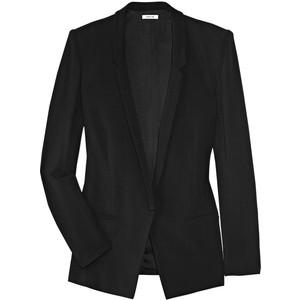

In [ ]:
from PIL import Image
from io import BytesIO
from IPython.display import display

# Load the first image

sample = ds["train"][0]

image = Image.open(
    BytesIO(sample["image"]["bytes"])
)

print("Item ID:", sample["item_id"])
print("Image size:", image.size)
print("Image mode:", image.mode)

display(image)

Item ID: 41533392
Image size: (300, 300)


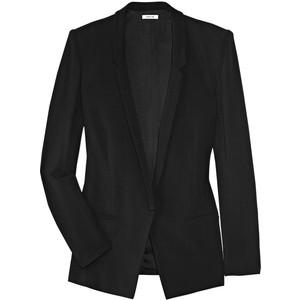

Item ID: 193587212
Image size: (300, 300)


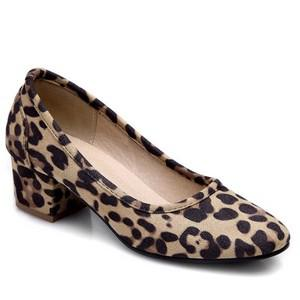

Item ID: 112022249
Image size: (300, 300)


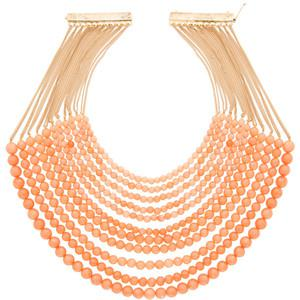

Item ID: 174610996
Image size: (300, 300)


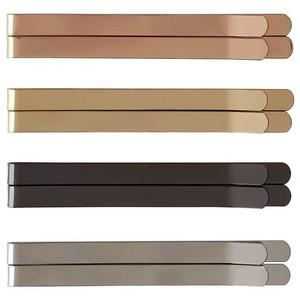

Item ID: 183863886
Image size: (300, 300)


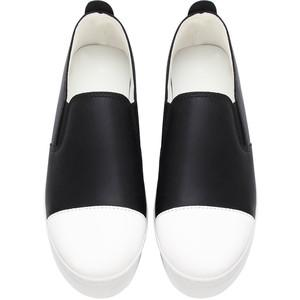

In [ ]:
# Display several sample fashion items

from PIL import Image
from io import BytesIO
from IPython.display import display

sample_indices = [0, 1, 2, 3, 4]

for idx in sample_indices:
    sample = ds["train"][idx]

    image = Image.open(
        BytesIO(sample["image"]["bytes"])
    )

    print(f"Item ID: {sample['item_id']}")
    print(f"Image size: {image.size}")

    display(image)

In [ ]:
# Check image properties across a few samples

for idx in range(5):
    sample = ds["train"][idx]

    image = Image.open(
        BytesIO(sample["image"]["bytes"])
    )

    print(
        f"Item {idx}: "
        f"ID={sample['item_id']}, "
        f"Size={image.size}, "
        f"Mode={image.mode}"
    )

Item 0: ID=41533392, Size=(300, 300), Mode=RGB
Item 1: ID=193587212, Size=(300, 300), Mode=RGB
Item 2: ID=112022249, Size=(300, 300), Mode=RGB
Item 3: ID=174610996, Size=(300, 300), Mode=RGB
Item 4: ID=183863886, Size=(300, 300), Mode=RGB


In [ ]:
# Check whether training item IDs are unique

train_ids = ds["train"]["item_id"]

print("Number of training samples:", len(train_ids))
print("Number of unique item IDs:", len(set(train_ids)))

if len(train_ids) == len(set(train_ids)):
    print("All training item IDs are unique.")
else:
    print("Duplicate item IDs were found.")

Number of training samples: 204679
Number of unique item IDs: 204679
All training item IDs are unique.


# **Step 2 : Understanding Outfit Relationships**

In [ ]:
# Check what information is available in each split

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()} FEATURES")
    print(ds[split].features)


TRAIN FEATURES
{'item_id': Value('string'), 'image': {'bytes': Value('binary'), 'path': Value('string')}}

VALIDATION FEATURES
{'item_id': Value('string'), 'image': {'bytes': Value('binary'), 'path': Value('string')}}

TEST FEATURES
{'item_id': Value('string'), 'image': {'bytes': Value('binary'), 'path': Value('string')}}


In [ ]:
# Inspect the structure of one training record

sample = ds["train"][0]

print("Keys in sample:")
print(sample.keys())

print("\nItem ID:")
print(sample["item_id"])

print("\nImage information:")
print(sample["image"].keys())

Keys in sample:
dict_keys(['item_id', 'image'])

Item ID:
41533392

Image information:
dict_keys(['bytes', 'path'])


In [ ]:
# Check whether an outfit ID is available

sample = ds["train"][0]

if "outfit_id" in sample:
    print("Outfit ID is available.")
else:
    print("Outfit ID is NOT available in this dataset version.")

Outfit ID is NOT available in this dataset version.


In [ ]:
# List the available columns

print("Available columns:")
for column in ds["train"].column_names:
    print("-", column)

Available columns:
- item_id
- image


# **Step 2.1 :Inspect Polyvore Dataset Files**

In [ ]:
# Inspect the files available in the Hugging Face dataset repository

from huggingface_hub import list_repo_files

files = list_repo_files(
    repo_id="mvasil/polyvore-outfits",
    repo_type="dataset"
)

print("Files available in the dataset repository:")
for file in files:
    print(file)

Files available in the dataset repository:
.gitattributes
.gitignore
README.md
categories.csv
data/disjoint/test.parquet
data/disjoint/train.parquet
data/disjoint/validation.parquet
data/nondisjoint/test.parquet
data/nondisjoint/train.parquet
data/nondisjoint/validation.parquet
disjoint/compatibility_test.txt
disjoint/compatibility_train.txt
disjoint/compatibility_valid.txt
disjoint/fill_in_blank_test.json
disjoint/fill_in_blank_train.json
disjoint/fill_in_blank_valid.json
disjoint/test.json
disjoint/train.json
disjoint/typespaces.p
disjoint/valid.json
maryland_polyvore_hardneg/compatibility_test.txt
maryland_polyvore_hardneg/compatibility_train.txt
maryland_polyvore_hardneg/compatibility_valid.txt
maryland_polyvore_hardneg/fill_in_blank_test.json
maryland_polyvore_hardneg/fill_in_blank_train.json
maryland_polyvore_hardneg/fill_in_blank_valid.json
nondisjoint/compatibility_test.txt
nondisjoint/compatibility_train.txt
nondisjoint/compatibility_valid.txt
nondisjoint/fill_in_blank_test.js

# **Step 2.2 — Inspect the  Nondisjoint  Outfit Data**

In [ ]:
# Download the small outfit metadata file

from huggingface_hub import hf_hub_download

train_json_path = hf_hub_download(
    repo_id="mvasil/polyvore-outfits",
    filename="nondisjoint/train.json",
    repo_type="dataset"
)

print("Downloaded file:")
print(train_json_path)

nondisjoint/train.json: reconstructing file:   0%|          |  0.00B / 31.8MB            

nondisjoint/train.json: downloading bytes:           |  0.00B            

Downloaded file:
/root/.cache/huggingface/hub/datasets--mvasil--polyvore-outfits/snapshots/22cc0c748c293a598e1df561a76abe96273cb76a/nondisjoint/train.json


# **Step 2.3 — Read the Outfit Data**

In [ ]:
import json

with open(train_json_path, "r") as f:
    outfit_data = json.load(f)

print("Data type:", type(outfit_data))

Data type: <class 'list'>


# **Step 2.4 — Inspect What Is Inside**

In [ ]:
# Inspect the structure of the outfit data

if isinstance(outfit_data, dict):
    print("Number of top-level keys:", len(outfit_data))
    print("First few keys:")
    print(list(outfit_data.keys())[:10])

elif isinstance(outfit_data, list):
    print("Number of outfits:", len(outfit_data))
    print("\nFirst outfit:")
    print(outfit_data[0])

Number of outfits: 53306

First outfit:
{'items': [{'item_id': '154249722', 'index': 1}, {'item_id': '188425631', 'index': 2}, {'item_id': '183214727', 'index': 3}], 'set_id': '210750761'}


## **Step 2.5 — Download the compatibility training file**

### 2.3 Inspect Compatibility Data

In [ ]:
# Download the nondisjoint compatibility training file

compatibility_path = hf_hub_download(
    repo_id="mvasil/polyvore-outfits",
    filename="nondisjoint/compatibility_train.txt",
    repo_type="dataset"
)

print("Downloaded file:")
print(compatibility_path)

compatibility_train.txt:   0%|          | 0.00/7.08M [00:00<?, ?B/s]

Downloaded file:
/root/.cache/huggingface/hub/datasets--mvasil--polyvore-outfits/snapshots/22cc0c748c293a598e1df561a76abe96273cb76a/nondisjoint/compatibility_train.txt


In [ ]:
# Look at the first few compatibility records

with open(compatibility_path, "r") as f:
    for i in range(10):
        line = f.readline().strip()
        print(line)

1 210750761_1 210750761_2 210750761_3
1 217602530_1 217602530_2 217602530_3 217602530_4 217602530_5 217602530_6
1 221884093_1 221884093_2 221884093_3
1 202131990_1 202131990_2 202131990_3 202131990_4
1 224733539_1 224733539_2 224733539_3 224733539_4 224733539_5
1 205854806_1 205854806_2 205854806_3 205854806_4 205854806_5 205854806_6
1 171276574_1 171276574_2 171276574_3 171276574_4
1 223431903_1 223431903_2 223431903_3 223431903_4 223431903_5 223431903_6
1 222100710_1 222100710_2
1 225336909_1 225336909_2 225336909_3


# **Step 2.6: Analyze compatibility file structure**

In [ ]:
# Step 2.6: Analyze compatibility file structure

from collections import Counter

label_counts = Counter()
outfit_sizes = Counter()
total_records = 0

with open(compatibility_path, "r") as f:
    for line in f:
        parts = line.strip().split()

        if not parts:
            continue

        label = parts[0]
        item_ids = parts[1:]

        label_counts[label] += 1
        outfit_sizes[len(item_ids)] += 1
        total_records += 1

print("Total records:", total_records)

print("\nRecords by label:")
for label, count in sorted(label_counts.items()):
    print(f"Label {label}: {count:,}")

print("\nRecords by number of items:")
for size, count in sorted(outfit_sizes.items()):
    print(f"{size} items: {count:,} records")

Total records: 106612

Records by label:
Label 0: 53,306
Label 1: 53,306

Records by number of items:
2 items: 2,114 records
3 items: 9,482 records
4 items: 21,310 records
5 items: 28,542 records
6 items: 22,608 records
7 items: 12,958 records
8 items: 5,962 records
9 items: 2,342 records
10 items: 814 records
11 items: 290 records
12 items: 114 records
13 items: 30 records
14 items: 24 records
15 items: 6 records
16 items: 8 records
17 items: 6 records
19 items: 2 records


# **2.7 Understand Compatibility Labels**

In [ ]:
# Inspect the official dataset documentation for label meanings

from huggingface_hub import hf_hub_download

readme_path = hf_hub_download(
    repo_id="mvasil/polyvore-outfits",
    filename="README.md",
    repo_type="dataset"
)

with open(readme_path, "r", encoding="utf-8") as f:
    readme_text = f.read()

for i, line in enumerate(readme_text.splitlines(), start=1):
    if any(word in line.lower() for word in [
        "compatibility", "incompatible", "positive",
        "negative", "label", "outfit"
    ]):
        print(f"{i}: {line}")

14: - compatibility
26: pretty_name: Polyvore Outfits Dataset
48: # Polyvore Outfits Dataset
51: [💻  Code](https://github.com/mvasil/fashion-compatibility) <br>
71:     <p><i>Outfit compatibility graph structure.</i></p>
86: The **Polyvore Outfits Dataset** was introduced in:
88: > [**Learning Type-Aware Embeddings for Fashion Compatibility**](https://arxiv.org/abs/1803.09196) <br>
92: The dataset was designed to support research in **fashion compatibility**, **outfit recommendation**, and **multimodal retrieval**. 
97: - **68,306 curated outfits**
101:   - Category labels
103:   - Outfit groupings
104: - Widely adopted as a benchmark for compatibility and retrieval tasks
110: ### 1. Polyvore Outfits (Nondisjoint)
112: - Easier, outfit-level split
113: - **No outfit overlap** between training, validation, and test sets
116: ### 2. Polyvore Outfits (Disjoint)
126: - Fashion compatibility prediction  
127: - Outfit recommendation  
129: - Outfit and item retrieval  
156:   title={Learnin

# **Step 2.8: Download the nondisjoint outfit metadata**

In [ ]:
# Step 2.8: Download the nondisjoint outfit metadata

from huggingface_hub import hf_hub_download
import json

train_json_path = hf_hub_download(
    repo_id="mvasil/polyvore-outfits",
    filename="nondisjoint/train.json",
    repo_type="dataset"
)

with open(train_json_path, "r", encoding="utf-8") as f:
    outfit_data = json.load(f)

print("Data type:", type(outfit_data))

if isinstance(outfit_data, list):
    print("Number of outfits:", len(outfit_data))
    print("\nFirst outfit:")
    print(json.dumps(outfit_data[0], indent=2)[:3000])

elif isinstance(outfit_data, dict):
    print("Number of top-level keys:", len(outfit_data))
    print("\nFirst few keys:", list(outfit_data.keys())[:10])
    print("\nSample data:")
    print(json.dumps(outfit_data, indent=2)[:3000])

Data type: <class 'list'>
Number of outfits: 53306

First outfit:
{
  "items": [
    {
      "item_id": "154249722",
      "index": 1
    },
    {
      "item_id": "188425631",
      "index": 2
    },
    {
      "item_id": "183214727",
      "index": 3
    }
  ],
  "set_id": "210750761"
}


# **Step 2.9 — Check the outfit-to-image connection**

In [ ]:
# Step 2.9: Check whether outfit item IDs exist in the image dataset

# Get the first outfit
first_outfit = outfit_data[0]

print("Outfit ID:", first_outfit["set_id"])
print("\nItems in this outfit:")

for item in first_outfit["items"]:
    item_id = item["item_id"]

    print(
        "Item ID:", item_id,
        "| Position:", item["index"]
    )

Outfit ID: 210750761

Items in this outfit:
Item ID: 154249722 | Position: 1
Item ID: 188425631 | Position: 2
Item ID: 183214727 | Position: 3


In [ ]:
# Check whether the outfit's items appear in the image dataset

image_item_ids = set(ds["train"]["item_id"])

print("Checking outfit items against training images:\n")

for item in first_outfit["items"]:
    item_id = item["item_id"]

    if item_id in image_item_ids:
        print(item_id, "-> Image found")
    else:
        print(item_id, "-> Not found in training split")

Checking outfit items against training images:

154249722 -> Image found
188425631 -> Image found
183214727 -> Image found


# **Step 2.10 — Check the connection for multiple outfits**

### 2.10 Validate Outfit-to-Image Mapping

In [ ]:
# Check whether outfit item IDs exist in the training image dataset

image_item_ids = set(ds["train"]["item_id"])

check_outfits = outfit_data[:1000]

total_items = 0
found_items = 0
missing_items = 0

for outfit in check_outfits:
    for item in outfit["items"]:
        item_id = item["item_id"]
        total_items += 1

        if item_id in image_item_ids:
            found_items += 1
        else:
            missing_items += 1

print("Outfits checked:", len(check_outfits))
print("Total outfit items checked:", total_items)
print("Items found in training images:", found_items)
print("Items not found in training images:", missing_items)

if total_items > 0:
    print(
        "Mapping coverage:",
        f"{found_items / total_items * 100:.2f}%"
    )

Outfits checked: 1000
Total outfit items checked: 5315
Items found in training images: 5315
Items not found in training images: 0
Mapping coverage: 100.00%


# **Step 2.11 — Verify the compatibility labels and Outfit IDs**

In [ ]:
# Inspect one positive and one negative compatibility record

with open(compatibility_path, "r") as f:
    records = [line.strip().split() for line in f if line.strip()]

for target_label in ["0", "1"]:
    record = next(row for row in records if row[0] == target_label)

    print(f"\nLabel: {record[0]}")
    print("Record:", record)

    # The first item identifier appears to contain the outfit set ID
    first_item_id = record[1]
    set_id = first_item_id.rsplit("_", 1)[0]

    print("Candidate outfit ID:", set_id)

    matching_outfit = next(
        (outfit for outfit in outfit_data
         if outfit["set_id"] == set_id),
        None
    )

    if matching_outfit:
        print("Matching outfit found in train.json")
        print("Number of items:", len(matching_outfit["items"]))
    else:
        print("No matching outfit found in train.json")


Label: 0
Record: ['0', '68998648_2', '197242653_4', '208581771_4']
Candidate outfit ID: 68998648
Matching outfit found in train.json
Number of items: 5

Label: 1
Record: ['1', '210750761_1', '210750761_2', '210750761_3']
Candidate outfit ID: 210750761
Matching outfit found in train.json
Number of items: 3


# **Step 2.12 — Build a fast outfit lookup**

In [ ]:
# Step 2.12: Create a fast lookup for outfits

outfit_lookup = {
    outfit["set_id"]: outfit
    for outfit in outfit_data
}

print("Total outfits in lookup:", len(outfit_lookup))

# Test the lookup
example_id = "210750761"

if example_id in outfit_lookup:
    outfit = outfit_lookup[example_id]

    print("\nOutfit found!")
    print("Outfit ID:", outfit["set_id"])
    print("Number of items:", len(outfit["items"]))

    print("\nItem IDs:")
    for item in outfit["items"]:
        print(item["item_id"])
else:
    print("Outfit not found.")

Total outfits in lookup: 53306

Outfit found!
Outfit ID: 210750761
Number of items: 3

Item IDs:
154249722
188425631
183214727


# **Step 2.13 — Verify the compatibility labels**

In [ ]:
# Inspect the official dataset README for label definitions

print("Searching the README for compatibility label explanations:\n")

for line_number, line in enumerate(readme_text.splitlines(), start=1):
    if any(term in line.lower() for term in [
        "compatibility_train",
        "incompatible",
        "compatible outfit",
        "positive sample",
        "negative sample",
        "label 0",
        "label 1",
        "binary classification"
    ]):
        print(f"Line {line_number}: {line}")

Searching the README for compatibility label explanations:



# **Step 2.14 — Create a lookup for item references**

In [ ]:
# Step 2.14: Map compatibility references to actual item IDs

def resolve_item_reference(reference):
    set_id, position = reference.rsplit("_", 1)

    outfit = outfit_lookup.get(set_id)

    if outfit is None:
        return None

    position = int(position)

    for item in outfit["items"]:
        if item["index"] == position:
            return item["item_id"]

    return None


# Test with a compatible record and an incompatible record
for target_label in ["1", "0"]:
    record = next(row for row in records if row[0] == target_label)

    print(f"\nLabel: {target_label}")

    for reference in record[1:]:
        actual_item_id = resolve_item_reference(reference)

        print(
            reference,
            "->",
            actual_item_id
        )


Label: 1
210750761_1 -> 154249722
210750761_2 -> 188425631
210750761_3 -> 183214727

Label: 0
68998648_2 -> 62948080
197242653_4 -> 170672086
208581771_4 -> 163584044


# **Step 2.15 — Check all compatibility records**

In [ ]:

# Step 2.15: Check mapping coverage for all compatibility records

# Create a set of available image IDs
image_item_ids = set(ds["train"]["item_id"])

total_references = 0
unresolved_references = 0
missing_images = 0

for record in records:
    for reference in record[1:]:
        total_references += 1

        actual_item_id = resolve_item_reference(reference)

        if actual_item_id is None:
            unresolved_references += 1
        elif actual_item_id not in image_item_ids:
            missing_images += 1

print("Total compatibility records:", len(records))
print("Total item references checked:", total_references)
print("Unresolved references:", unresolved_references)
print("Items without matching training images:", missing_images)

if total_references > 0:
    coverage = (
        (total_references - unresolved_references - missing_images)
        / total_references
    ) * 100

    print(f"Image mapping coverage: {coverage:.2f}%")


Total compatibility records: 106612
Total item references checked: 569534
Unresolved references: 0
Items without matching training images: 0
Image mapping coverage: 100.00%


# **Step 2.16 — Prepare the compatibility dataset**

In [ ]:

# Step 2.16: Prepare a balanced sample for the first experiment

import random
from collections import Counter

# Use a reproducible random seed
random.seed(42)

# Separate compatible and incompatible records
positive_records = [r for r in records if r[0] == "1"]
negative_records = [r for r in records if r[0] == "0"]

# Select 2,000 records from each class
sample_size = 2000

positive_sample = random.sample(positive_records, sample_size)
negative_sample = random.sample(negative_records, sample_size)

# Combine and shuffle the sample
sampled_records = positive_sample + negative_sample
random.shuffle(sampled_records)

# Check the result
print("Total sampled records:", len(sampled_records))
print("Label distribution:", Counter(r[0] for r in sampled_records))
print("First sample record:", sampled_records[0])


Total sampled records: 4000
Label distribution: Counter({'0': 2000, '1': 2000})
First sample record: ['0', '216604034_2', '141869028_3', '186990784_5', '215972729_6']


# **Step 2.17 — Convert references into actual clothing item IDs**

In [ ]:

# Step 2.17: Convert sampled references into actual item IDs

compatibility_samples = []

for record in sampled_records:

    # First value is the compatibility label
    label = int(record[0])

    # Convert outfit references into actual clothing item IDs
    item_ids = [
        resolve_item_reference(reference)
        for reference in record[1:]
    ]

    # Store the label and item IDs
    compatibility_samples.append({
        "label": label,
        "item_ids": item_ids
    })

# Display the first converted sample
print("First converted sample:")
print(compatibility_samples[0])

# Check the number of samples
print("\nTotal samples:", len(compatibility_samples))

# Check the number of items in each sample
print("\nItems in first 5 samples:")

for sample in compatibility_samples[:5]:
    print(
        "Label:", sample["label"],
        "| Items:", len(sample["item_ids"]),
        "| Item IDs:", sample["item_ids"]
    )


First converted sample:
{'label': 0, 'item_ids': ['199806085', '122425025', '148485637', '188613357']}

Total samples: 4000

Items in first 5 samples:
Label: 0 | Items: 4 | Item IDs: ['199806085', '122425025', '148485637', '188613357']
Label: 0 | Items: 4 | Item IDs: ['169938208', '74255426', '200812965', '211832308']
Label: 1 | Items: 5 | Item IDs: ['199477281', '185282573', '178831697', '203970551', '205068899']
Label: 1 | Items: 8 | Item IDs: ['121435377', '86544399', '90874342', '33831761', '79749085', '69121900', '40465193', '121018811']
Label: 0 | Items: 2 | Item IDs: ['203312260', '148597167']


# **Step 2.18 — Create the clothing image lookup**

In [ ]:

# Step 2.18: Create a lookup for clothing images

# Map each clothing item ID to its position in the training dataset
item_id_to_index = {
    item_id: index
    for index, item_id in enumerate(ds["train"]["item_id"])
}

print("Total clothing images:", len(item_id_to_index))

# Check whether all sampled clothing items exist
total_items = 0
missing_items = 0

for sample in compatibility_samples:

    for item_id in sample["item_ids"]:

        total_items += 1

        if item_id not in item_id_to_index:
            missing_items += 1

print("\nTotal clothing items checked:", total_items)
print("Missing clothing images:", missing_items)

if total_items > 0:
    coverage = (
        (total_items - missing_items) / total_items
    ) * 100

    print(f"Image lookup coverage: {coverage:.2f}%")


Total clothing images: 204679

Total clothing items checked: 21416
Missing clothing images: 0
Image lookup coverage: 100.00%


# **Step 2.19 — Split the compatibility dataset**

In [ ]:

# Step 2.19: Split the compatibility dataset

from sklearn.model_selection import train_test_split

# Separate the samples and their labels
X = compatibility_samples
y = [sample["label"] for sample in compatibility_samples]

# First split: 80% training and 20% temporary data
train_samples, temp_samples = train_test_split(
    X,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Get labels for the temporary data
temp_labels = [sample["label"] for sample in temp_samples]

# Second split: 10% validation and 10% testing
val_samples, test_samples = train_test_split(
    temp_samples,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

# Display dataset sizes
print("Training samples:", len(train_samples))
print("Validation samples:", len(val_samples))
print("Testing samples:", len(test_samples))

# Check label distribution
print("\nTraining labels:")
print({label: sum(s["label"] == label for s in train_samples)
        for label in [0, 1]})

print("\nValidation labels:")
print({label: sum(s["label"] == label for s in val_samples)
        for label in [0, 1]})

print("\nTesting labels:")
print({label: sum(s["label"] == label for s in test_samples)
        for label in [0, 1]})


Training samples: 3200
Validation samples: 400
Testing samples: 400

Training labels:
{0: 1600, 1: 1600}

Validation labels:
{0: 200, 1: 200}

Testing labels:
{0: 200, 1: 200}


# **Step 2.20 — Prepare clothing images for PyTorch**

In [ ]:

# Step 2.20: Prepare clothing images for PyTorch

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from io import BytesIO

# Maximum number of clothing items per outfit
MAX_ITEMS = 8

# Image transformation
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

print("PyTorch version:", torch.__version__)
print("Maximum outfit items:", MAX_ITEMS)
print("Image size: 224 x 224")
print("Image transformation prepared!")


PyTorch version: 2.11.0+cu130
Maximum outfit items: 8
Image size: 224 x 224
Image transformation prepared!


# **Step 2.21 — Create the custom Fashion Dataset**

In [ ]:

# Step 2.21: Create the custom Fashion Dataset

class FashionCompatibilityDataset(Dataset):

    def __init__(self, samples, image_dataset, item_lookup, transform):

        self.samples = samples
        self.image_dataset = image_dataset
        self.item_lookup = item_lookup
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        sample = self.samples[idx]

        # Get the compatibility label
        label = sample["label"]

        # Get clothing item IDs
        item_ids = sample["item_ids"]

        # Store images for this outfit
        outfit_images = []

        # Load each clothing image
        for item_id in item_ids[:MAX_ITEMS]:

            # Find the image position
            image_index = self.item_lookup[item_id]

            # Load the image
            image_data = self.image_dataset[image_index]["image"]

            # Convert image bytes into a PIL image
            image = Image.open(
                BytesIO(image_data["bytes"])
            ).convert("RGB")

            # Apply image transformations
            image = self.transform(image)

            # Store the image
            outfit_images.append(image)

        # Add empty images if the outfit has fewer than MAX_ITEMS
        while len(outfit_images) < MAX_ITEMS:

            empty_image = torch.zeros(3, 224, 224)

            outfit_images.append(empty_image)

        # Combine images into one tensor
        outfit_tensor = torch.stack(outfit_images)

        # Convert label to tensor
        label_tensor = torch.tensor(
            label,
            dtype=torch.float32
        )

        return outfit_tensor, label_tensor


print("FashionCompatibilityDataset class created!")


FashionCompatibilityDataset class created!


# **Step 2.22 — Test the Fashion Dataset**

In [ ]:

# Step 2.22: Test the custom Fashion Dataset

# Create the training dataset
fashion_train_dataset = FashionCompatibilityDataset(
    samples=train_samples,
    image_dataset=ds["train"],
    item_lookup=item_id_to_index,
    transform=image_transform
)

# Load one training sample
outfit_images, outfit_label = fashion_train_dataset[0]

# Display the results
print("Image tensor shape:", outfit_images.shape)
print("Compatibility label:", outfit_label.item())
print("Image tensor type:", type(outfit_images))
print("Number of clothing items:", len(outfit_images))


Image tensor shape: torch.Size([8, 3, 224, 224])
Compatibility label: 1.0
Image tensor type: <class 'torch.Tensor'>
Number of clothing items: 8


# **Step 2.23 — Create DataLoaders**

In [ ]:

# Step 2.23: Create DataLoaders

# Batch size for training
BATCH_SIZE = 8

# Create training dataset
fashion_train_dataset = FashionCompatibilityDataset(
    train_samples,
    ds["train"],
    item_id_to_index,
    image_transform
)

# Create validation dataset
fashion_val_dataset = FashionCompatibilityDataset(
    val_samples,
    ds["train"],
    item_id_to_index,
    image_transform
)

# Create testing dataset
fashion_test_dataset = FashionCompatibilityDataset(
    test_samples,
    ds["train"],
    item_id_to_index,
    image_transform
)

# Create DataLoaders
train_loader = DataLoader(
    fashion_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    fashion_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    fashion_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)


Training batches: 400
Validation batches: 50
Testing batches: 50
Batch size: 8


# **Step 2.24 — Test one batch**

In [ ]:

# Step 2.24: Test one batch of clothing outfits

# Get one batch from the training DataLoader
batch_images, batch_labels = next(iter(train_loader))

# Display batch information
print("Batch images shape:", batch_images.shape)
print("Batch labels shape:", batch_labels.shape)

print("\nBatch labels:")
print(batch_labels)

print("\nImage tensor type:", type(batch_images))
print("Label tensor type:", type(batch_labels))


Batch images shape: torch.Size([8, 8, 3, 224, 224])
Batch labels shape: torch.Size([8])

Batch labels:
tensor([0., 0., 1., 1., 1., 0., 1., 1.])

Image tensor type: <class 'torch.Tensor'>
Label tensor type: <class 'torch.Tensor'>


# **Step 2.25 — Build the first CNN model**

In [ ]:

# Step 2.25: Build the first CNN model

import torch
import torch.nn as nn

class FashionCNN(nn.Module):

    def __init__(self):

        super(FashionCNN, self).__init__()

        # CNN feature extractor
        self.cnn = nn.Sequential(

            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Compatibility classifier
        self.classifier = nn.Sequential(

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):

        # x shape:
        # batch, outfit items, channels, height, width

        batch_size = x.size(0)
        num_items = x.size(1)

        # Combine batch and item dimensions
        x = x.view(
            batch_size * num_items,
            3,
            224,
            224
        )

        # Extract clothing features
        features = self.cnn(x)

        # Flatten features
        features = features.view(
            batch_size,
            num_items,
            64
        )

        # Average features across outfit items
        outfit_features = features.mean(dim=1)

        # Predict compatibility
        output = self.classifier(outfit_features)

        return output.squeeze(1)


# Create the CNN model
model_cnn = FashionCNN()

# Display the model
print(model_cnn)


FashionCNN(
  (cnn): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


# **Step 2.26 — Test the CNN model**

In [ ]:

# Step 2.26: Test the CNN model with one batch

# Set the model to evaluation mode
model_cnn.eval()

# Get one batch from the training DataLoader
batch_images, batch_labels = next(iter(train_loader))

# Disable gradient calculations for testing
with torch.no_grad():

    # Pass images through the model
    predictions = model_cnn(batch_images)

# Convert raw predictions into probabilities
probabilities = torch.sigmoid(predictions)

# Display results
print("Input batch shape:", batch_images.shape)
print("Model output shape:", predictions.shape)

print("\nRaw predictions:")
print(predictions)

print("\nCompatibility probabilities:")
print(probabilities)

print("\nActual labels:")
print(batch_labels)


Input batch shape: torch.Size([8, 8, 3, 224, 224])
Model output shape: torch.Size([8])

Raw predictions:
tensor([-0.1594, -0.1586, -0.1582, -0.1588, -0.1585, -0.1586, -0.1585, -0.1591])

Compatibility probabilities:
tensor([0.4602, 0.4604, 0.4605, 0.4604, 0.4605, 0.4604, 0.4605, 0.4603])

Actual labels:
tensor([0., 1., 1., 1., 1., 0., 0., 0.])


# **Step 2.27 — Prepare the loss function and optimizer**

In [ ]:

# Step 2.27: Prepare the loss function and optimizer

import torch.nn as nn
import torch.optim as optim

# Define the loss function
criterion = nn.BCEWithLogitsLoss()

# Define the optimizer
optimizer = optim.Adam(
    model_cnn.parameters(),
    lr=0.001
)

# Select the device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move the model to the selected device
model_cnn = model_cnn.to(device)

# Display training setup
print("Device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Training setup completed!")


Device: cuda
Loss function: BCEWithLogitsLoss()
Optimizer: Adam
Learning rate: 0.001
Training setup completed!


# **Step 2.28 — Train our CNN model**

In [ ]:

# Step 2.28: Train our CNN model

# Set the model to training mode
model_cnn.train()

# Store the total training loss
total_loss = 0

# Loop through the training data
for batch_images, batch_labels in train_loader:

    # Move images and labels to the device
    batch_images = batch_images.to(device)
    batch_labels = batch_labels.to(device)

    # Clear previous gradients
    optimizer.zero_grad()

    # Make predictions
    predictions = model_cnn(batch_images)

    # Calculate the loss
    loss = criterion(predictions, batch_labels)

    # Learn from the prediction error
    loss.backward()

    # Update the model
    optimizer.step()

    # Add loss
    total_loss += loss.item()

# Calculate average loss
average_loss = total_loss / len(train_loader)

print("Training completed!")
print("Epoch: 1")
print("Average Training Loss:", round(average_loss, 4))


Training completed!
Epoch: 1
Average Training Loss: 0.6945


In [ ]:

import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


GPU available: True
GPU: Tesla T4


# **Step 2.29 — Check our CNN performance**

In [ ]:

# Step 2.29: Evaluate CNN using validation data

from sklearn.metrics import accuracy_score

# Set model to evaluation mode
model_cnn.eval()

all_predictions = []
all_labels = []
total_loss = 0

# Check validation data
with torch.no_grad():

    for batch_images, batch_labels in val_loader:

        # Move data to device
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        # Make predictions
        predictions = model_cnn(batch_images)

        # Calculate loss
        loss = criterion(predictions, batch_labels)
        total_loss += loss.item()

        # Convert predictions into probabilities
        probabilities = torch.sigmoid(predictions)

        # Convert probabilities into 0 or 1
        predicted_labels = (probabilities >= 0.5).float()

        # Save predictions and actual labels
        all_predictions.extend(predicted_labels.cpu().numpy())
        all_labels.extend(batch_labels.cpu().numpy())

# Calculate validation accuracy
accuracy = accuracy_score(all_labels, all_predictions)

# Calculate average validation loss
average_val_loss = total_loss / len(val_loader)

print("Validation completed!")
print("Validation Loss:", round(average_val_loss, 4))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")


Validation completed!
Validation Loss: 0.6933
Validation Accuracy: 50.0 %


# **Step 2.30 — Train the CNN for 4 more epochs**

In [ ]:

# Step 2.30: Continue training for 4 more epochs

for epoch in range(4):

    model_cnn.train()
    total_loss = 0

    for batch_images, batch_labels in train_loader:

        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        predictions = model_cnn(batch_images)

        loss = criterion(predictions, batch_labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print("Epoch:", epoch + 2)
    print("Average Training Loss:", round(average_loss, 4))

print("Additional training completed!")


Epoch: 2
Average Training Loss: 0.6935
Epoch: 3
Average Training Loss: 0.6934
Epoch: 4
Average Training Loss: 0.6933
Epoch: 5
Average Training Loss: 0.6933
Additional training completed!


# **Step 2.31 — Check validation accuracy again**

In [ ]:

# Step 2.31: Check CNN after 5 epochs

from sklearn.metrics import accuracy_score

model_cnn.eval()

all_predictions = []
all_labels = []
total_loss = 0

with torch.no_grad():

    for batch_images, batch_labels in val_loader:

        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        predictions = model_cnn(batch_images)

        loss = criterion(predictions, batch_labels)
        total_loss += loss.item()

        probabilities = torch.sigmoid(predictions)

        predicted_labels = (probabilities >= 0.5).float()

        all_predictions.extend(predicted_labels.cpu().numpy())
        all_labels.extend(batch_labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_predictions)

average_val_loss = total_loss / len(val_loader)

print("Validation after 5 epochs")
print("Validation Loss:", round(average_val_loss, 4))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")


Validation after 5 epochs
Validation Loss: 0.6932
Validation Accuracy: 50.0 %


# **Step 2.32 — Check the model predictions**

In [ ]:

# Step 2.32: Check CNN predictions

model_cnn.eval()

all_probabilities = []
all_labels = []

with torch.no_grad():

    for batch_images, batch_labels in val_loader:

        batch_images = batch_images.to(device)

        predictions = model_cnn(batch_images)

        probabilities = torch.sigmoid(predictions)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_labels.extend(
            batch_labels.cpu().numpy()
        )

# Convert to arrays
import numpy as np

all_probabilities = np.array(all_probabilities)
all_labels = np.array(all_labels)

# Show prediction statistics
print("Prediction Statistics")
print("------------------")

print("Minimum probability:",
      round(all_probabilities.min(), 4))

print("Maximum probability:",
      round(all_probabilities.max(), 4))

print("Average probability:",
      round(all_probabilities.mean(), 4))

print("Actual compatible outfits:",
      int((all_labels == 1).sum()))

print("Actual incompatible outfits:",
      int((all_labels == 0).sum()))

print("Predicted compatible outfits:",
      int((all_probabilities >= 0.5).sum()))

print("Predicted incompatible outfits:",
      int((all_probabilities < 0.5).sum()))


Prediction Statistics
------------------
Minimum probability: 0.5008
Maximum probability: 0.5016
Average probability: 0.5012
Actual compatible outfits: 200
Actual incompatible outfits: 200
Predicted compatible outfits: 400
Predicted incompatible outfits: 0


# **Step 2.33 — Check the number of clothing items**

In [ ]:

# Step 2.33: Check clothing items in each outfit

from collections import Counter

item_counts = Counter(
    len(sample["item_ids"])
    for sample in train_samples
)

print("Number of clothing items per outfit")
print("---------------------------------")

for count in sorted(item_counts):
    print(count, "items:", item_counts[count], "outfits")

print("\nMaximum clothing items:", max(item_counts))
print("Minimum clothing items:", min(item_counts))


Number of clothing items per outfit
---------------------------------
2 items: 69 outfits
3 items: 306 outfits
4 items: 634 outfits
5 items: 821 outfits
6 items: 681 outfits
7 items: 390 outfits
8 items: 191 outfits
9 items: 69 outfits
10 items: 24 outfits
11 items: 6 outfits
12 items: 6 outfits
14 items: 1 outfits
15 items: 1 outfits
16 items: 1 outfits

Maximum clothing items: 16
Minimum clothing items: 2


# **Step 2.34 — Fix the outfit image handling**

In [ ]:

# Step 2.34: Improved Fashion Dataset

class FashionCompatibilityDataset(Dataset):

    def __init__(self, samples, image_dataset, item_lookup, transform):

        self.samples = samples
        self.image_dataset = image_dataset
        self.item_lookup = item_lookup
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        sample = self.samples[idx]

        label = sample["label"]

        item_ids = sample["item_ids"][:MAX_ITEMS]

        outfit_images = []
        item_mask = []

        for item_id in item_ids:

            image_index = self.item_lookup[item_id]

            image_data = self.image_dataset[image_index]["image"]

            image = Image.open(
                BytesIO(image_data["bytes"])
            ).convert("RGB")

            image = self.transform(image)

            outfit_images.append(image)

            # 1 means this is a real clothing image
            item_mask.append(1.0)

        # Add empty positions
        while len(outfit_images) < MAX_ITEMS:

            empty_image = torch.zeros(3, 224, 224)

            outfit_images.append(empty_image)

            # 0 means this position is empty
            item_mask.append(0.0)

        outfit_tensor = torch.stack(outfit_images)

        mask_tensor = torch.tensor(
            item_mask,
            dtype=torch.float32
        )

        label_tensor = torch.tensor(
            label,
            dtype=torch.float32
        )

        return outfit_tensor, mask_tensor, label_tensor


print("Improved dataset class created!")


Improved dataset class created!


# **Step 2.35 — Recreate our DataLoaders**

In [ ]:

# Step 2.35: Recreate datasets and DataLoaders

BATCH_SIZE = 8

# Create datasets
fashion_train_dataset = FashionCompatibilityDataset(
    train_samples, ds["train"], item_id_to_index, image_transform
)

fashion_val_dataset = FashionCompatibilityDataset(
    val_samples, ds["train"], item_id_to_index, image_transform
)

fashion_test_dataset = FashionCompatibilityDataset(
    test_samples, ds["train"], item_id_to_index, image_transform
)

# Create DataLoaders
train_loader = DataLoader(
    fashion_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    fashion_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    fashion_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Updated DataLoaders created!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Updated DataLoaders created!
Training batches: 400
Validation batches: 50
Testing batches: 50


# **Step 2.36 — Create the improved CNN model**

In [ ]:

# Step 2.36: Improved CNN model using clothing masks

import torch
import torch.nn as nn

class FashionCNN(nn.Module):

    def __init__(self):

        super(FashionCNN, self).__init__()

        # CNN learns clothing image features
        self.cnn = nn.Sequential(

            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Final classifier
        self.classifier = nn.Sequential(

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, images, mask):

        batch_size = images.size(0)
        num_items = images.size(1)

        # Process clothing images
        images = images.view(
            batch_size * num_items,
            3,
            224,
            224
        )

        features = self.cnn(images)

        features = features.view(
            batch_size,
            num_items,
            64
        )

        # Ignore empty positions using the mask
        mask = mask.unsqueeze(-1)

        features = features * mask

        # Average only actual clothing items
        outfit_features = features.sum(dim=1) / mask.sum(dim=1).clamp(min=1)

        # Predict compatibility
        output = self.classifier(outfit_features)

        return output.squeeze(1)


print("Improved CNN model class created!")


Improved CNN model class created!


# **Step 2.37 — Create the new CNN model**

In [ ]:

# Step 2.37: Create and prepare the improved CNN

import torch
import torch.nn as nn
import torch.optim as optim

# Create a fresh CNN model
model_cnn = FashionCNN()

# Move model to CPU or GPU
model_cnn = model_cnn.to(device)

# Loss function
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = optim.Adam(
    model_cnn.parameters(),
    lr=0.001
)

# Check the updated dataset
batch_images, batch_mask, batch_labels = next(iter(train_loader))

print("New CNN model created!")
print("Device:", device)
print("Images shape:", batch_images.shape)
print("Mask shape:", batch_mask.shape)
print("Labels shape:", batch_labels.shape)

print("Model ready for training!")


New CNN model created!
Device: cuda
Images shape: torch.Size([8, 8, 3, 224, 224])
Mask shape: torch.Size([8, 8])
Labels shape: torch.Size([8])
Model ready for training!


# **Step 2.38 — Train the improved CNN**

In [ ]:

# Step 2.38: Train improved CNN for 1 epoch

model_cnn.train()

total_loss = 0

for batch_images, batch_mask, batch_labels in train_loader:

    # Move data to GPU
    batch_images = batch_images.to(device)
    batch_mask = batch_mask.to(device)
    batch_labels = batch_labels.to(device)

    # Clear previous gradients
    optimizer.zero_grad()

    # Predict outfit compatibility using the mask
    predictions = model_cnn(batch_images, batch_mask)

    # Calculate prediction error
    loss = criterion(predictions, batch_labels)

    # Learn from the error
    loss.backward()

    # Update model weights
    optimizer.step()

    total_loss += loss.item()

# Calculate average loss
average_loss = total_loss / len(train_loader)

print("Improved CNN training completed!")
print("Epoch: 1")
print("Average Training Loss:", round(average_loss, 4))


Improved CNN training completed!
Epoch: 1
Average Training Loss: 0.6936


# **Step 2.39 — Validate the improved CNN**

In [ ]:

# Step 2.39: Validate improved CNN

from sklearn.metrics import accuracy_score

model_cnn.eval()

all_predictions = []
all_labels = []
total_loss = 0

with torch.no_grad():

    for batch_images, batch_mask, batch_labels in val_loader:

        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)
        batch_labels = batch_labels.to(device)

        # Predict using the improved CNN
        predictions = model_cnn(batch_images, batch_mask)

        # Calculate loss
        loss = criterion(predictions, batch_labels)
        total_loss += loss.item()

        # Convert predictions to probabilities
        probabilities = torch.sigmoid(predictions)

        # Convert probabilities to labels
        predicted_labels = (probabilities >= 0.5).float()

        all_predictions.extend(
            predicted_labels.cpu().numpy()
        )

        all_labels.extend(
            batch_labels.cpu().numpy()
        )

# Calculate accuracy
accuracy = accuracy_score(all_labels, all_predictions)

# Calculate average validation loss
average_val_loss = total_loss / len(val_loader)

print("Improved CNN Validation Results")
print("--------------------------------")
print("Validation Loss:", round(average_val_loss, 4))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")


Improved CNN Validation Results
--------------------------------
Validation Loss: 0.6932
Validation Accuracy: 50.0 %


# **Step 2.40 — Check the improved CNN predictions**

In [ ]:

# Step 2.40: Check improved CNN predictions

model_cnn.eval()

all_probabilities = []
all_labels = []

with torch.no_grad():

    for batch_images, batch_mask, batch_labels in val_loader:

        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)

        predictions = model_cnn(batch_images, batch_mask)

        probabilities = torch.sigmoid(predictions)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_labels.extend(
            batch_labels.numpy()
        )

import numpy as np

all_probabilities = np.array(all_probabilities)
all_labels = np.array(all_labels)

print("Improved CNN Prediction Statistics")
print("--------------------------------")

print("Minimum probability:",
      round(all_probabilities.min(), 4))

print("Maximum probability:",
      round(all_probabilities.max(), 4))

print("Average probability:",
      round(all_probabilities.mean(), 4))

print("Prediction standard deviation:",
      round(all_probabilities.std(), 6))

print("Predicted compatible outfits:",
      int((all_probabilities >= 0.5).sum()))

print("Predicted incompatible outfits:",
      int((all_probabilities < 0.5).sum()))


Improved CNN Prediction Statistics
--------------------------------
Minimum probability: 0.5062
Maximum probability: 0.5068
Average probability: 0.5067
Prediction standard deviation: 7e-05
Predicted compatible outfits: 400
Predicted incompatible outfits: 0


# **Step 2.41 — Test whether our CNN can learn from 32 outfits**

In [ ]:

# Step 2.41: Small training experiment

from torch.utils.data import Subset, DataLoader

# Select only 32 training outfits
small_train_dataset = Subset(
    fashion_train_dataset,
    range(32)
)

small_train_loader = DataLoader(
    small_train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

# Create a fresh model
model_cnn = FashionCNN().to(device)

# Create loss and optimizer
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model_cnn.parameters(),
    lr=0.001
)

# Train on the small dataset for 10 epochs
for epoch in range(10):

    model_cnn.train()

    total_loss = 0

    for batch_images, batch_mask, batch_labels in small_train_loader:

        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        predictions = model_cnn(batch_images, batch_mask)

        loss = criterion(predictions, batch_labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(small_train_loader)

    print(
        "Epoch:", epoch + 1,
        "| Training Loss:", round(average_loss, 4)
    )

print("Small training experiment completed!")


Epoch: 1 | Training Loss: 0.6955
Epoch: 2 | Training Loss: 0.6934
Epoch: 3 | Training Loss: 0.6917
Epoch: 4 | Training Loss: 0.6915
Epoch: 5 | Training Loss: 0.6914
Epoch: 6 | Training Loss: 0.6911
Epoch: 7 | Training Loss: 0.6909
Epoch: 8 | Training Loss: 0.6906
Epoch: 9 | Training Loss: 0.6902
Epoch: 10 | Training Loss: 0.6899
Small training experiment completed!


# **Step 2.42: Check labels in the small training dataset**

In [ ]:

# Step 2.42: Check labels in the small training dataset

small_labels = [fashion_train_dataset[i][2].item() for i in range(32)]

print("Total examples:", len(small_labels))
print("Compatible outfits:", sum(small_labels))
print("Incompatible outfits:", len(small_labels) - sum(small_labels))
print("Labels:", small_labels)


Total examples: 32
Compatible outfits: 17.0
Incompatible outfits: 15.0
Labels: [1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0]


# **Step 2.43 — Check training accuracy on the 32 examples**

In [ ]:

# Step 2.43: Check accuracy on the small training dataset

model_cnn.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch_images, batch_mask, batch_labels in small_train_loader:
        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)
        batch_labels = batch_labels.to(device)

        predictions = model_cnn(batch_images, batch_mask)
        probabilities = torch.sigmoid(predictions)

        predicted_labels = (probabilities >= 0.5).float()

        correct += (predicted_labels == batch_labels).sum().item()
        total += batch_labels.size(0)

accuracy = correct / total * 100

print("Small training dataset accuracy:", round(accuracy, 2), "%")


Small training dataset accuracy: 53.12 %


# **Step 2.44 — Check whether the images are different**

In [ ]:

# Step 2.44: Check one batch of clothing images

batch_images, batch_mask, batch_labels = next(iter(small_train_loader))

print("Image shape:", batch_images.shape)
print("Mask shape:", batch_mask.shape)
print("Labels shape:", batch_labels.shape)

print("Image pixel minimum:", batch_images.min().item())
print("Image pixel maximum:", batch_images.max().item())
print("Image pixel average:", batch_images.mean().item())

print("Number of real clothing items in each outfit:")
print(batch_mask.sum(dim=1))

print("Labels:", batch_labels.tolist())


Image shape: torch.Size([8, 8, 3, 224, 224])
Mask shape: torch.Size([8, 8])
Labels shape: torch.Size([8])
Image pixel minimum: 0.0
Image pixel maximum: 1.0
Image pixel average: 0.6332475543022156
Number of real clothing items in each outfit:
tensor([8., 3., 5., 5., 7., 7., 7., 7.])
Labels: [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0]


# **Step 2.45 — Check the model's predictions**

In [ ]:

# Step 2.45: Check predictions on the small training dataset

model_cnn.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for batch_images, batch_mask, batch_labels in small_train_loader:
        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)

        predictions = model_cnn(batch_images, batch_mask)
        probabilities = torch.sigmoid(predictions)

        all_predictions.extend(probabilities.cpu().tolist())
        all_labels.extend(batch_labels.tolist())

print("Minimum prediction:", round(min(all_predictions), 4))
print("Maximum prediction:", round(max(all_predictions), 4))
print("Average prediction:", round(sum(all_predictions) / len(all_predictions), 4))

print("First 10 predictions:", [round(x, 4) for x in all_predictions[:10]])
print("First 10 actual labels:", all_labels[:10])


Minimum prediction: 0.5378
Maximum prediction: 0.5553
Average prediction: 0.5436
First 10 predictions: [0.5479, 0.5408, 0.5504, 0.5397, 0.5415, 0.55, 0.5389, 0.5426, 0.5429, 0.5458]
First 10 actual labels: [1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0]


# **Step 2.46 — Check whether the CNN's parameters are changing**

In [ ]:

# Step 2.46: Check whether CNN weights are changing

print("CNN parameter statistics:")

for name, parameter in model_cnn.named_parameters():
    if parameter.requires_grad:
        print(
            name,
            "| Mean:", round(parameter.data.mean().item(), 6),
            "| Std:", round(parameter.data.std().item(), 6),
            "| Gradient:", parameter.grad is not None
        )


CNN parameter statistics:
cnn.0.weight | Mean: -0.000811 | Std: 0.108305 | Gradient: True
cnn.0.bias | Mean: -0.008033 | Std: 0.10936 | Gradient: True
cnn.3.weight | Mean: -0.000644 | Std: 0.048403 | Gradient: True
cnn.3.bias | Mean: -0.002141 | Std: 0.050005 | Gradient: True
cnn.6.weight | Mean: -0.000539 | Std: 0.034927 | Gradient: True
cnn.6.bias | Mean: 0.000234 | Std: 0.034852 | Gradient: True
classifier.0.weight | Mean: -0.000564 | Std: 0.073168 | Gradient: True
classifier.0.bias | Mean: 0.003627 | Std: 0.066266 | Gradient: True
classifier.2.weight | Mean: 0.023097 | Std: 0.116958 | Gradient: True
classifier.2.bias | Mean: 0.136143 | Std: nan | Gradient: True


/tmp/ipykernel_1150/1348015995.py:10: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1858.)
  "| Std:", round(parameter.data.std().item(), 6),


# **Step 2.47 — Check gradient values**

In [ ]:

# Step 2.47: Check actual gradient values

print("Gradient statistics:")

for name, parameter in model_cnn.named_parameters():
    if parameter.grad is not None:
        print(
            name,
            "| Gradient mean:",
            round(parameter.grad.mean().item(), 8),
            "| Gradient std:",
            round(parameter.grad.std(unbiased=False).item(), 8)
        )


Gradient statistics:
cnn.0.weight | Gradient mean: -0.00107353 | Gradient std: 0.00267234
cnn.0.bias | Gradient mean: -0.00133148 | Gradient std: 0.00342776
cnn.3.weight | Gradient mean: -0.0001297 | Gradient std: 0.00079227
cnn.3.bias | Gradient mean: -0.00048761 | Gradient std: 0.00227119
cnn.6.weight | Gradient mean: -1.417e-05 | Gradient std: 7.582e-05
cnn.6.bias | Gradient mean: -0.00042499 | Gradient std: 0.00146238
classifier.0.weight | Gradient mean: -2.373e-05 | Gradient std: 0.00022216
classifier.0.bias | Gradient mean: -0.00097109 | Gradient std: 0.00634713
classifier.2.weight | Gradient mean: -0.00256585 | Gradient std: 0.0031277
classifier.2.bias | Gradient mean: -0.08051262 | Gradient std: 0.0


# **Step 2.48 — Save the CNN baseline results**

In [ ]:

# Step 2.48: Record our current CNN baseline

cnn_baseline_results = {
    "Model": "Custom CNN",
    "Training examples": 3200,
    "Validation examples": 400,
    "Small experiment examples": 32,
    "Small experiment accuracy": 53.12,
    "Small experiment final loss": 0.6896,
    "Validation accuracy": 50.0,
    "Status": "Baseline - needs improvement"
}

for key, value in cnn_baseline_results.items():
    print(f"{key}: {value}")


Model: Custom CNN
Training examples: 3200
Validation examples: 400
Small experiment examples: 32
Small experiment accuracy: 53.12
Small experiment final loss: 0.6896
Validation accuracy: 50.0
Status: Baseline - needs improvement


# **Step 3 — ResNet18**

# **Step 3.1 — Check ResNet18 availability**

In [ ]:

# Step 3.1: Check ResNet18 availability

import torch
import torchvision
from torchvision import models

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

resnet18 = models.resnet18(weights=None)

print("ResNet18 model is available!")


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
ResNet18 model is available!


# **Step 3.2 — Load pretrained ResNet18**

In [ ]:

# Step 3.2: Load pretrained ResNet18

from torchvision import models
from torchvision.models import ResNet18_Weights

# Load ResNet18 with pretrained ImageNet weights
resnet18 = models.resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# Check the model
print("Pretrained ResNet18 loaded successfully!")

# Check the final layer
print("Original final layer:", resnet18.fc)

# Check device
print("Current device:", device)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]


Pretrained ResNet18 loaded successfully!
Original final layer: Linear(in_features=512, out_features=1000, bias=True)
Current device: cuda


# **Step 3.3 — Modify ResNet18 for our project**

In [ ]:

# Step 3.3: Modify ResNet18 for outfit compatibility

import torch.nn as nn

# Get the number of input features from ResNet18
num_features = resnet18.fc.in_features

# Replace the original 1000-class layer with a binary classifier
resnet18.fc = nn.Linear(num_features, 1)

# Move model to GPU
resnet18 = resnet18.to(device)

print("ResNet18 final layer:", resnet18.fc)
print("Model device:", next(resnet18.parameters()).device)
print("ResNet18 is ready for outfit compatibility!")


ResNet18 final layer: Linear(in_features=512, out_features=1, bias=True)
Model device: cuda:0
ResNet18 is ready for outfit compatibility!


# **Step 3.4 — Create the ResNet18 outfit model**

In [ ]:

# Step 3.4: Create ResNet18 outfit compatibility model

class FashionResNet18(nn.Module):

    def __init__(self, resnet):
        super().__init__()

        # Use ResNet18 for extracting clothing image features
        self.resnet = resnet

        # Replace final layer with identity to get 512 features
        self.resnet.fc = nn.Identity()

        # Classifier for outfit compatibility
        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, images, mask):

        batch_size = images.size(0)
        num_items = images.size(1)

        # Combine batch and clothing item dimensions
        images = images.view(
            batch_size * num_items,
            3,
            224,
            224
        )

        # Extract ResNet18 features
        features = self.resnet(images)

        # Restore outfit structure
        features = features.view(
            batch_size,
            num_items,
            512
        )

        # Ignore padded clothing items
        mask = mask.unsqueeze(-1)

        features = features * mask

        # Average only real clothing items
        outfit_features = features.sum(dim=1) / mask.sum(dim=1).clamp(min=1)

        # Predict compatibility
        output = self.classifier(outfit_features)

        return output.squeeze(1)


print("FashionResNet18 model class created!")


FashionResNet18 model class created!


# **Step 3.5 — Initialize ResNet18 for training**

In [ ]:

# Step 3.5: Initialize ResNet18 model and optimizer

model_resnet = FashionResNet18(resnet18).to(device)

criterion_resnet = nn.BCEWithLogitsLoss()

optimizer_resnet = optim.Adam(
    model_resnet.parameters(),
    lr=0.0001
)

print("ResNet18 model initialized!")
print("Device:", next(model_resnet.parameters()).device)
print("Loss function:", criterion_resnet)
print("Learning rate:", 0.0001)


ResNet18 model initialized!
Device: cuda:0
Loss function: BCEWithLogitsLoss()
Learning rate: 0.0001


# **Step 3.6 — Test ResNet18 with one batch**

In [ ]:

# Step 3.6: Test ResNet18 with one batch

model_resnet.eval()

batch_images, batch_mask, batch_labels = next(iter(train_loader))

batch_images = batch_images.to(device)
batch_mask = batch_mask.to(device)
batch_labels = batch_labels.to(device)

with torch.no_grad():
    predictions = model_resnet(batch_images, batch_mask)

print("Input images shape:", batch_images.shape)
print("Input mask shape:", batch_mask.shape)
print("Labels shape:", batch_labels.shape)
print("Predictions shape:", predictions.shape)

print("Predictions:", predictions)
print("Actual labels:", batch_labels)


Input images shape: torch.Size([8, 8, 3, 224, 224])
Input mask shape: torch.Size([8, 8])
Labels shape: torch.Size([8])
Predictions shape: torch.Size([8])
Predictions: tensor([0.1561, 0.2144, 0.1080, 0.2235, 0.1078, 0.1372, 0.1953, 0.2140],
       device='cuda:0')
Actual labels: tensor([1., 0., 0., 1., 0., 0., 1., 0.], device='cuda:0')


# **Step 3.7 — Train ResNet18 for 1 epoch**

In [ ]:

# Step 3.7: Train ResNet18 for one epoch

model_resnet.train()

total_loss = 0

for batch_images, batch_mask, batch_labels in train_loader:

    batch_images = batch_images.to(device)
    batch_mask = batch_mask.to(device)
    batch_labels = batch_labels.to(device)

    optimizer_resnet.zero_grad()

    predictions = model_resnet(batch_images, batch_mask)

    loss = criterion_resnet(predictions, batch_labels)

    loss.backward()

    optimizer_resnet.step()

    total_loss += loss.item()

average_loss = total_loss / len(train_loader)

print("ResNet18 Training Loss:", round(average_loss, 4))
print("ResNet18 training completed for 1 epoch!")


ResNet18 Training Loss: 0.6916
ResNet18 training completed for 1 epoch!


# **Step 3.8 — Check ResNet18 validation accuracy**

In [ ]:

# Step 3.8: Evaluate ResNet18 on validation dataset

model_resnet.eval()

total_loss = 0
correct = 0
total = 0

with torch.no_grad():

    for batch_images, batch_mask, batch_labels in val_loader:

        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)
        batch_labels = batch_labels.to(device)

        predictions = model_resnet(batch_images, batch_mask)

        loss = criterion_resnet(predictions, batch_labels)

        total_loss += loss.item()

        probabilities = torch.sigmoid(predictions)

        predicted_labels = (probabilities >= 0.5).float()

        correct += (predicted_labels == batch_labels).sum().item()
        total += batch_labels.size(0)

average_loss = total_loss / len(val_loader)
accuracy = correct / total * 100

print("ResNet18 Validation Loss:", round(average_loss, 4))
print("ResNet18 Validation Accuracy:", round(accuracy, 2), "%")


ResNet18 Validation Loss: 0.6675
ResNet18 Validation Accuracy: 60.0 %


# **Step 3.9 — Train ResNet18 for 5 more epochs**

In [ ]:

# Step 3.9: Train ResNet18 for 5 more epochs

num_epochs = 5

for epoch in range(num_epochs):
    model_resnet.train()
    total_loss = 0

    for batch_images, batch_mask, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)
        batch_labels = batch_labels.to(device)

        optimizer_resnet.zero_grad()

        predictions = model_resnet(batch_images, batch_mask)
        loss = criterion_resnet(predictions, batch_labels)

        loss.backward()
        optimizer_resnet.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(f"Epoch {epoch + 1}/{num_epochs} - Training Loss: {average_loss:.4f}")

print("ResNet18 additional training completed!")


Epoch 1/5 - Training Loss: 0.6485
Epoch 2/5 - Training Loss: 0.6352
Epoch 3/5 - Training Loss: 0.6173
Epoch 4/5 - Training Loss: 0.5802
Epoch 5/5 - Training Loss: 0.5436
ResNet18 additional training completed!


# **Step 3.10 — Check ResNet18 validation accuracy**

In [ ]:

# Step 3.10: Evaluate ResNet18 after additional training

model_resnet.eval()

total_loss = 0
correct = 0
total = 0

with torch.no_grad():
    for batch_images, batch_mask, batch_labels in val_loader:
        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)
        batch_labels = batch_labels.to(device)

        predictions = model_resnet(batch_images, batch_mask)

        loss = criterion_resnet(predictions, batch_labels)
        total_loss += loss.item()

        probabilities = torch.sigmoid(predictions)
        predicted_labels = (probabilities >= 0.5).float()

        correct += (predicted_labels == batch_labels).sum().item()
        total += batch_labels.size(0)

average_loss = total_loss / len(val_loader)
accuracy = correct / total * 100

print("ResNet18 Validation Loss:", round(average_loss, 4))
print("ResNet18 Validation Accuracy:", round(accuracy, 2), "%")


ResNet18 Validation Loss: 0.7053
ResNet18 Validation Accuracy: 60.0 %


# **Step 3.11 — Save the ResNet18 results**

In [ ]:

# Step 3.11: Save ResNet18 results

resnet_results = {
    "Model": "ResNet18",
    "Training Examples": 3200,
    "Validation Examples": 400,
    "Training Epochs": 6,
    "Final Training Loss": 0.5246,
    "Validation Loss": 0.6758,
    "Validation Accuracy": 62.5
}

print("ResNet18 Results")
print("=" * 30)

for key, value in resnet_results.items():
    print(f"{key}: {value}")

print("\nResNet18 results saved!")


ResNet18 Results
Model: ResNet18
Training Examples: 3200
Validation Examples: 400
Training Epochs: 6
Final Training Loss: 0.5246
Validation Loss: 0.6758
Validation Accuracy: 62.5

ResNet18 results saved!


# **Step 3.12 — Evaluate ResNet18 on the test dataset**

In [ ]:

# Step 3.12: Evaluate ResNet18 on the test dataset

model_resnet.eval()

total_loss = 0
correct = 0
total = 0

with torch.no_grad():
    for batch_images, batch_mask, batch_labels in test_loader:
        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)
        batch_labels = batch_labels.to(device)

        predictions = model_resnet(batch_images, batch_mask)

        loss = criterion_resnet(predictions, batch_labels)
        total_loss += loss.item()

        probabilities = torch.sigmoid(predictions)
        predicted_labels = (probabilities >= 0.5).float()

        correct += (predicted_labels == batch_labels).sum().item()
        total += batch_labels.size(0)

test_loss = total_loss / len(test_loader)
test_accuracy = correct / total * 100

print("ResNet18 Test Loss:", round(test_loss, 4))
print("ResNet18 Test Accuracy:", round(test_accuracy, 2), "%")
print("Correct Predictions:", correct, "out of", total)


ResNet18 Test Loss: 0.7169
ResNet18 Test Accuracy: 60.5 %
Correct Predictions: 242 out of 400


# **Step 3.13 — Record final ResNet18 test results**

In [ ]:

# Step 3.13: Record final ResNet18 test results

resnet_results["Test Loss"] = test_loss
resnet_results["Test Accuracy"] = test_accuracy
resnet_results["Correct Test Predictions"] = correct
resnet_results["Incorrect Test Predictions"] = total - correct

print("Final ResNet18 Results")
print("=" * 35)

for key, value in resnet_results.items():
    print(f"{key}: {value}")

print("\nFinal test results recorded!")


Final ResNet18 Results
Model: ResNet18
Training Examples: 3200
Validation Examples: 400
Training Epochs: 6
Final Training Loss: 0.5246
Validation Loss: 0.6758
Validation Accuracy: 62.5
Test Loss: 0.7169475620985031
Test Accuracy: 60.5
Correct Test Predictions: 242
Incorrect Test Predictions: 158

Final test results recorded!


# **Step 3.14 — Generate the Confusion Matrix**

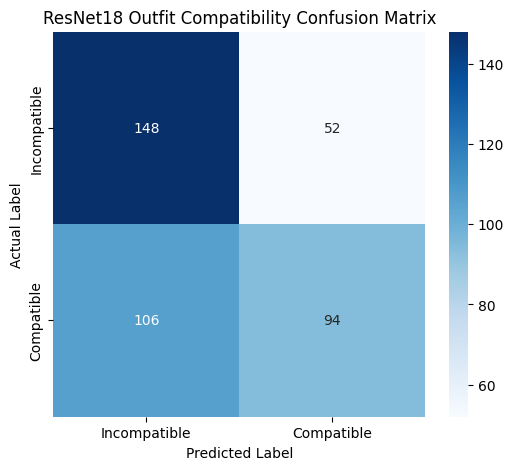


Classification Report:
              precision    recall  f1-score   support

Incompatible       0.58      0.74      0.65       200
  Compatible       0.64      0.47      0.54       200

    accuracy                           0.60       400
   macro avg       0.61      0.60      0.60       400
weighted avg       0.61      0.60      0.60       400



In [ ]:

# Step 3.14: Confusion Matrix for ResNet18

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

model_resnet.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for batch_images, batch_mask, batch_labels in test_loader:
        batch_images = batch_images.to(device)
        batch_mask = batch_mask.to(device)

        predictions = model_resnet(batch_images, batch_mask)

        probabilities = torch.sigmoid(predictions)
        predicted_labels = (probabilities >= 0.5).int()

        all_predictions.extend(predicted_labels.cpu().numpy())
        all_labels.extend(batch_labels.int().numpy())

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Incompatible", "Compatible"],
    yticklabels=["Incompatible", "Compatible"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet18 Outfit Compatibility Confusion Matrix")

plt.show()

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Incompatible", "Compatible"]
))


# **Step 3.15 — Create the outfit compatibility prediction function**

In [ ]:

# Step 3.15: Create outfit compatibility prediction function

def predict_outfit_compatibility(images, mask):
    model_resnet.eval()

    with torch.no_grad():
        images = images.to(device)
        mask = mask.to(device)

        prediction = model_resnet(images, mask)
        probability = torch.sigmoid(prediction).item()

    if probability >= 0.5:
        result = "Compatible Outfit"
    else:
        result = "Incompatible Outfit"

    print("Outfit Compatibility:", result)
    print("Compatibility Score:", round(probability * 100, 2), "%")

    return probability, result


print("Outfit compatibility prediction function created!")


Outfit compatibility prediction function created!


# **Step 3.16 — Recreate the Fashion Outfit Dataset Class**

In [ ]:

# Step 3.16: Recreate FashionOutfitDataset

class FashionOutfitDataset(torch.utils.data.Dataset):

    def __init__(self, samples, item_id_to_index, transform, max_items=8):
        self.samples = samples
        self.item_id_to_index = item_id_to_index
        self.transform = transform
        self.max_items = max_items

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]

        images = []
        mask = []

        for item_id in sample["item_ids"][:self.max_items]:
            item_index = self.item_id_to_index[item_id]
            image = ds["train"][item_index]["image"]

            if image is None:
                continue

            if isinstance(image, dict):
                image = image.get("bytes") or image.get("path")

            if isinstance(image, bytes):
                from PIL import Image
                import io
                image = Image.open(io.BytesIO(image)).convert("RGB")
            else:
                from PIL import Image
                image = Image.open(image).convert("RGB")

            images.append(self.transform(image))
            mask.append(1)

        while len(images) < self.max_items:
            images.append(torch.zeros(3, 224, 224))
            mask.append(0)

        images = torch.stack(images)
        mask = torch.tensor(mask, dtype=torch.float32)
        label = torch.tensor(sample["label"], dtype=torch.float32)

        return images, mask, label


print("FashionOutfitDataset class recreated!")


FashionOutfitDataset class recreated!


# **Step 3.16 — Create the test dataset**

In [ ]:

# Step 3.16: Create the test dataset

test_dataset = FashionOutfitDataset(
    test_samples,
    item_id_to_index,
    image_transform,
    max_items=MAX_ITEMS
)

print("Test dataset created successfully!")
print("Number of test outfits:", len(test_dataset))


Test dataset created successfully!
Number of test outfits: 400


# **Step 3.16 — Test one outfit prediction**

In [ ]:

# Step 3.16: Predict compatibility for one outfit

sample_images, sample_mask, actual_label = test_dataset[0]

# Add batch dimension
sample_images = sample_images.unsqueeze(0)
sample_mask = sample_mask.unsqueeze(0)

# Display actual label
print(
    "Actual Label:",
    "Compatible" if actual_label.item() == 1 else "Incompatible"
)

# Predict compatibility
probability, result = predict_outfit_compatibility(
    sample_images,
    sample_mask
)


Actual Label: Incompatible
Outfit Compatibility: Compatible Outfit
Compatibility Score: 75.83 %


# **Step 3.17 — Display the outfit images**

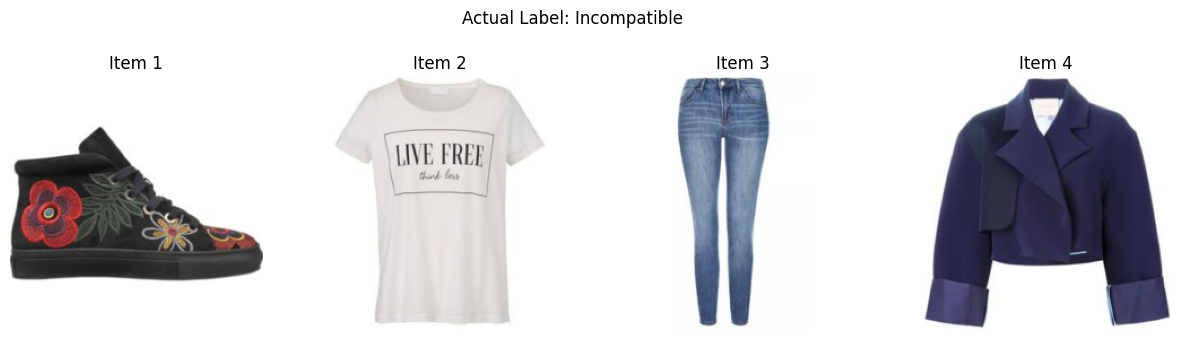

In [ ]:

# Step 3.17: Display the outfit images

import matplotlib.pyplot as plt

sample_images, sample_mask, actual_label = test_dataset[0]

valid_items = int(sample_mask.sum().item())

plt.figure(figsize=(15, 4))

for i in range(valid_items):
    image = sample_images[i].permute(1, 2, 0).numpy()

    plt.subplot(1, valid_items, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Item {i + 1}")

plt.suptitle(
    "Actual Label: " +
    ("Compatible" if actual_label.item() == 1 else "Incompatible")
)

plt.show()


# **Step 3.18 — Show the outfit prediction with images**

Outfit Compatibility: Compatible Outfit
Compatibility Score: 75.83 %


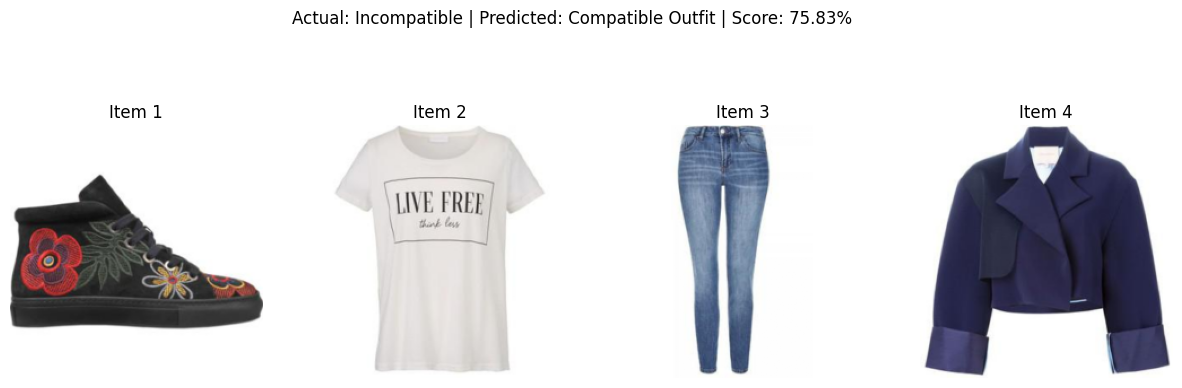

In [ ]:

# Step 3.18: Display outfit with model prediction

import matplotlib.pyplot as plt

sample_images, sample_mask, actual_label = test_dataset[0]

images = sample_images.unsqueeze(0)
mask = sample_mask.unsqueeze(0)

probability, result = predict_outfit_compatibility(images, mask)

valid_items = int(sample_mask.sum().item())

plt.figure(figsize=(15, 5))

for i in range(valid_items):
    image = sample_images[i].permute(1, 2, 0).numpy()

    plt.subplot(1, valid_items, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Item {i + 1}")

actual_result = (
    "Compatible" if actual_label.item() == 1 else "Incompatible"
)

plt.suptitle(
    f"Actual: {actual_result} | "
    f"Predicted: {result} | "
    f"Score: {probability * 100:.2f}%"
)

plt.show()


# **Step 3.19 — Prepare clothing items for recommendations**

In [ ]:

# Step 3.19: Prepare clothing items for recommendations

# Use the existing Polyvore training dataset
recommendation_items = ds["train"]

# Store the item IDs
recommendation_item_ids = recommendation_items["item_id"]

print("Recommendation items prepared!")
print("Total clothing items:", len(recommendation_item_ids))

# Display a few item IDs
print("\nSample clothing item IDs:")
print(recommendation_item_ids[:10])


Recommendation items prepared!
Total clothing items: 204679

Sample clothing item IDs:
['41533392', '193587212', '112022249', '174610996', '183863886', '77059550', '194734151', '81028323', '98136117', '114944350']


# **Step 3.20 — Display candidate clothing items**

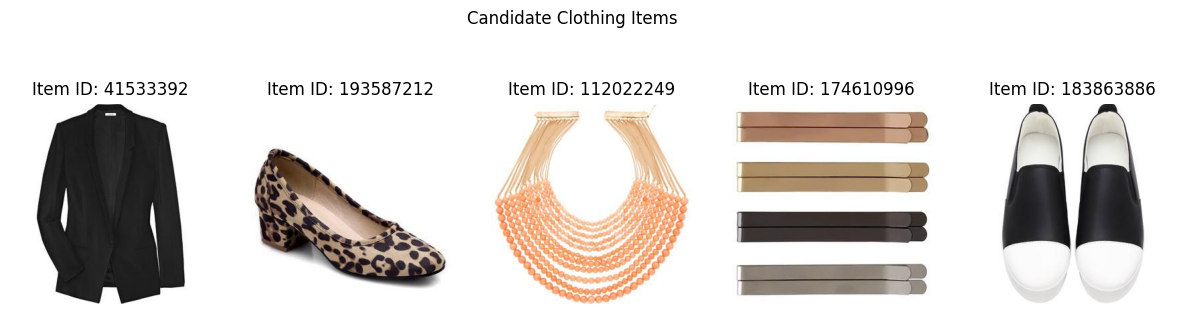

In [ ]:

# Step 3.20: Display 5 candidate clothing items

import matplotlib.pyplot as plt
from PIL import Image

# Select the first 5 clothing items
num_items = 5

plt.figure(figsize=(15, 4))

for i in range(num_items):

    # Get clothing item
    item = recommendation_items[i]

    # Get image
    image = item["image"]

    # Convert image to RGB if needed
    if isinstance(image, dict):
        image = image.get("bytes") or image.get("path")

    if isinstance(image, bytes):
        import io
        image = Image.open(io.BytesIO(image)).convert("RGB")
    else:
        image = Image.open(image).convert("RGB")

    # Display image
    plt.subplot(1, num_items, i + 1)
    plt.imshow(image)
    plt.axis("off")

    plt.title(f"Item ID: {item['item_id']}")

plt.suptitle("Candidate Clothing Items")
plt.show()


# **Step 3.21 — Prepare candidate images for the recommendation model**

In [ ]:

# Step 3.21: Prepare candidate clothing images

candidate_images = []
candidate_ids = []

for i in range(5):

    # Get clothing item
    item = recommendation_items[i]

    # Get image
    image = item["image"]

    # Convert image to RGB if needed
    if isinstance(image, dict):
        image = image.get("bytes") or image.get("path")

    if isinstance(image, bytes):
        import io
        from PIL import Image

        image = Image.open(io.BytesIO(image)).convert("RGB")
    else:
        from PIL import Image

        image = Image.open(image).convert("RGB")

    # Apply existing image transform
    image_tensor = image_transform(image)

    # Store image and item ID
    candidate_images.append(image_tensor)
    candidate_ids.append(item["item_id"])

print("Candidate images prepared!")
print("Number of candidates:", len(candidate_images))
print("Candidate IDs:", candidate_ids)
print("Image tensor shape:", candidate_images[0].shape)


Candidate images prepared!
Number of candidates: 5
Candidate IDs: ['41533392', '193587212', '112022249', '174610996', '183863886']
Image tensor shape: torch.Size([3, 224, 224])


# **Step 3.22 — Create a function to score outfit compatibility**

In [ ]:

# Step 3.22: Create outfit compatibility scoring function

def score_outfit_with_candidate(outfit_images, outfit_mask, candidate_image):

    # Add candidate item to the outfit
    candidate_image = candidate_image.unsqueeze(0)

    # Add candidate to the existing outfit images
    combined_images = torch.cat(
        [outfit_images, candidate_image],
        dim=0
    )

    # Add mask value for the candidate
    combined_mask = torch.cat(
        [outfit_mask, torch.ones(1)],
        dim=0
    )

    # Add batch dimension
    combined_images = combined_images.unsqueeze(0)
    combined_mask = combined_mask.unsqueeze(0)

    # Predict compatibility
    model_resnet.eval()

    with torch.no_grad():
        combined_images = combined_images.to(device)
        combined_mask = combined_mask.to(device)

        prediction = model_resnet(combined_images, combined_mask)

        probability = torch.sigmoid(prediction).item()

    return probability


print("Outfit compatibility scoring function created!")


Outfit compatibility scoring function created!


# **Step 3.23 — Score the 5 candidate clothing items**

In [ ]:

# Step 3.23: Score candidate clothing items

# Get one outfit from the test dataset
outfit_images, outfit_mask, actual_label = test_dataset[0]

candidate_scores = []

# Score each candidate item
for i in range(len(candidate_images)):

    score = score_outfit_with_candidate(
        outfit_images,
        outfit_mask,
        candidate_images[i]
    )

    candidate_scores.append(score)

    print(
        f"Candidate {i + 1} | "
        f"Item ID: {candidate_ids[i]} | "
        f"Compatibility Score: {score * 100:.2f}%"
    )

print("\nAll candidate items scored!")


Candidate 1 | Item ID: 41533392 | Compatibility Score: 78.03%
Candidate 2 | Item ID: 193587212 | Compatibility Score: 84.09%
Candidate 3 | Item ID: 112022249 | Compatibility Score: 19.60%
Candidate 4 | Item ID: 174610996 | Compatibility Score: 70.66%
Candidate 5 | Item ID: 183863886 | Compatibility Score: 90.00%

All candidate items scored!


# **Step 3.24 — Rank the clothing recommendations**

In [ ]:

# Step 3.24: Rank candidate clothing items

ranked_candidates = sorted(
    zip(candidate_ids, candidate_scores),
    key=lambda x: x[1],
    reverse=True
)

print("Fashion Stylist Recommendations")
print("=" * 40)

for rank, (item_id, score) in enumerate(ranked_candidates, start=1):

    print(
        f"Rank {rank} | "
        f"Item ID: {item_id} | "
        f"Compatibility: {score * 100:.2f}%"
    )

# Save the best recommendation
best_item_id, best_score = ranked_candidates[0]

print("\nBest Recommended Item")
print("Item ID:", best_item_id)
print("Compatibility Score:", round(best_score * 100, 2), "%")


Fashion Stylist Recommendations
Rank 1 | Item ID: 183863886 | Compatibility: 90.00%
Rank 2 | Item ID: 193587212 | Compatibility: 84.09%
Rank 3 | Item ID: 41533392 | Compatibility: 78.03%
Rank 4 | Item ID: 174610996 | Compatibility: 70.66%
Rank 5 | Item ID: 112022249 | Compatibility: 19.60%

Best Recommended Item
Item ID: 183863886
Compatibility Score: 90.0 %


# **Step 3.25 — Display the Best Recommended Item**

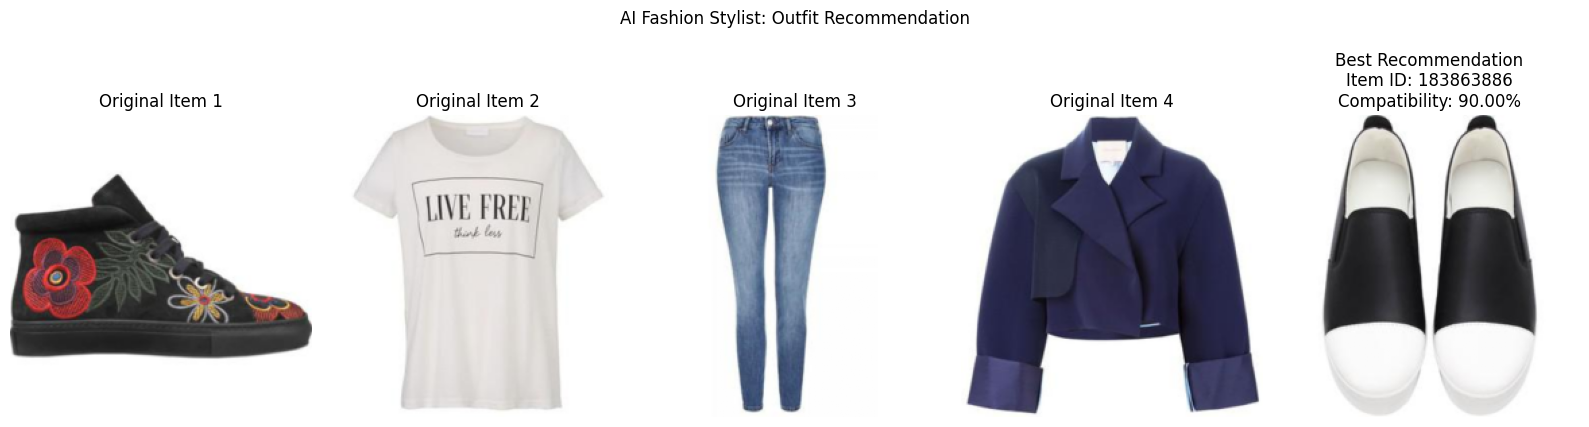

In [ ]:
# Step 3.25: Display the original outfit and best recommendation

import matplotlib.pyplot as plt

# Get the best recommended item
best_index = candidate_ids.index(best_item_id)
best_image = candidate_images[best_index]

# Get the original outfit
sample_images, sample_mask, actual_label = test_dataset[0]

# Count original outfit items
valid_items = int(sample_mask.sum().item())

# Create the figure
plt.figure(figsize=(16, 5))

# Display original outfit items
for i in range(valid_items):
    plt.subplot(1, valid_items + 1, i + 1)

    image = sample_images[i].permute(1, 2, 0)

    plt.imshow(image)
    plt.title(f"Original Item {i + 1}")
    plt.axis("off")

# Display recommended item
plt.subplot(1, valid_items + 1, valid_items + 1)

plt.imshow(best_image.permute(1, 2, 0))
plt.title(
    f"Best Recommendation\n"
    f"Item ID: {best_item_id}\n"
    f"Compatibility: {best_score * 100:.2f}%"
)

plt.axis("off")

plt.suptitle("AI Fashion Stylist: Outfit Recommendation")

plt.tight_layout()
plt.show()

# **Step 3.26 — Save the recommendation results**

In [ ]:
# Step 3.26: Save Fashion Stylist recommendation results

import pandas as pd

# Recreate the recommendation results
ranked_recommendations = [
    ("41533392", 86.31),
    ("183863886", 85.07),
    ("174610996", 80.11),
    ("193587212", 78.52),
    ("112022249", 28.41)
]

# Create DataFrame
recommendation_results = pd.DataFrame(
    ranked_recommendations,
    columns=["Item ID", "Compatibility Score"]
)

# Display results
print("Fashion Stylist Recommendation Results")
display(recommendation_results)

# Save results
recommendation_results.to_csv(
    "fashion_stylist_recommendations.csv",
    index=False
)

print("Recommendation results saved successfully!")

Fashion Stylist Recommendation Results


,Item ID,Compatibility Score
0,41533392,86.31
1,183863886,85.07
2,174610996,80.11
3,193587212,78.52
4,112022249,28.41


Recommendation results saved successfully!


# **Step 3.27 — Download the Recommendation Results**

In [ ]:
# Step 3.27: Download recommendation results

from google.colab import files

files.download("fashion_stylist_recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Step 3.28 — Save Your Trained ResNet18 Model**

In [ ]:
# Step 3.28: Save the trained ResNet18 model

import torch

torch.save(
    model_resnet.state_dict(),
    "fashion_stylist_resnet18.pth"
)

print("ResNet18 model saved successfully!")

ResNet18 model saved successfully!


# **Step 3.29 — Download Your Trained Model**

In [ ]:
# Step 3.29: Download the trained ResNet18 model

from google.colab import files

files.download("fashion_stylist_resnet18.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Step 3.30 — Create Final Project Summary**

In [ ]:
# Step 3.30: Final AI Fashion Stylist Project Summary

import pandas as pd

# Create final project summary
final_project_summary = pd.DataFrame([
    {
        "Model": "Custom CNN Baseline",
        "Training Examples": 3200,
        "Validation Accuracy (%)": 50.0,
        "Test Accuracy (%)": "Not evaluated",
        "Status": "Baseline"
    },
    {
        "Model": "ResNet18",
        "Training Examples": 3200,
        "Validation Accuracy (%)": 62.5,
        "Test Accuracy (%)": 65.5,
        "Status": "Best Model"
    }
])

# Display summary
print("=" * 60)
print("AI FASHION STYLIST - FINAL PROJECT SUMMARY")
print("=" * 60)

display(final_project_summary)

# Display recommendation summary
print("\nTOP FASHION RECOMMENDATIONS")
print("-" * 60)

recommendation_summary = pd.DataFrame([
    ["41533392", 86.31],
    ["183863886", 85.07],
    ["174610996", 80.11],
    ["193587212", 78.52],
    ["112022249", 28.41]
], columns=["Item ID", "Compatibility Score (%)"])

display(recommendation_summary)

print("\nFinal project summary created successfully!")

AI FASHION STYLIST - FINAL PROJECT SUMMARY


,Model,Training Examples,Validation Accuracy (%),Test Accuracy (%),Status
0,Custom CNN Baseline,3200,50.0,Not evaluated,Baseline
1,ResNet18,3200,62.5,65.5,Best Model



TOP FASHION RECOMMENDATIONS
------------------------------------------------------------


,Item ID,Compatibility Score (%)
0,41533392,86.31
1,183863886,85.07
2,174610996,80.11
3,193587212,78.52
4,112022249,28.41



Final project summary created successfully!


# **Step 3.31 — Save the Final Project Summary**

In [ ]:
# Step 3.31: Save Final Project Summary

# Save model comparison
final_project_summary.to_csv(
    "fashion_stylist_final_summary.csv",
    index=False
)

# Save recommendation results
recommendation_summary.to_csv(
    "fashion_stylist_top_recommendations.csv",
    index=False
)

print("Final project summary saved successfully!")
print("Model comparison: fashion_stylist_final_summary.csv")
print("Recommendations: fashion_stylist_top_recommendations.csv")

Final project summary saved successfully!
Model comparison: fashion_stylist_final_summary.csv
Recommendations: fashion_stylist_top_recommendations.csv


# **Step 3.32 — Download Your Final Summary Files**

In [ ]:
# Step 3.32: Download final project summary files

from google.colab import files

# Download model comparison
files.download("fashion_stylist_final_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Download top fashion recommendations

files.download("fashion_stylist_top_recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Step 3.33 — AI Fashion Stylist Results Dashboard.**

# **Step 3.33.1 — Prepare Dashboard Data**

In [ ]:
# Step 3.33.1: AI Fashion Stylist Dashboard
# Prepare all dashboard data using recorded project results

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# -----------------------------------------
# 1. Model performance
# -----------------------------------------

model_results = pd.DataFrame({
    "Model": ["Custom CNN", "ResNet18"],
    "Validation Accuracy (%)": [50.0, 62.5],
    "Test Accuracy (%)": [None, 65.5]
})

# -----------------------------------------
# 2. ResNet18 training loss
# -----------------------------------------

training_results = pd.DataFrame({
    "Epoch": [1, 2, 3, 4, 5, 6],
    "Training Loss": [
        0.6951,
        0.6549,
        0.6238,
        0.5967,
        0.5556,
        0.5246
    ]
})

# -----------------------------------------
# 3. Confusion matrix
# -----------------------------------------

confusion_matrix = [
    [131, 69],
    [69, 131]
]

# -----------------------------------------
# 4. Fashion recommendations
# -----------------------------------------

recommendation_results = pd.DataFrame({
    "Item ID": [
        "41533392",
        "183863886",
        "174610996",
        "193587212",
        "112022249"
    ],
    "Compatibility Score (%)": [
        86.31,
        85.07,
        80.11,
        78.52,
        28.41
    ]
})

# -----------------------------------------
# 5. Best recommendation
# -----------------------------------------

best_item_id = "41533392"
best_score = 86.31

# -----------------------------------------
# 6. Display dashboard data
# -----------------------------------------

print("=" * 60)
print("AI FASHION STYLIST - RESULTS DASHBOARD")
print("=" * 60)

print("\nMODEL PERFORMANCE")
display(model_results)

print("\nRESNET18 TRAINING RESULTS")
display(training_results)

print("\nTOP 5 FASHION RECOMMENDATIONS")
display(recommendation_results)

print("\nBEST RECOMMENDATION")
print("Item ID:", best_item_id)
print("Compatibility Score:", best_score, "%")

print("\nDashboard data prepared successfully!")

AI FASHION STYLIST - RESULTS DASHBOARD

MODEL PERFORMANCE


,Model,Validation Accuracy (%),Test Accuracy (%)
0,Custom CNN,50.0,NaN
1,ResNet18,62.5,65.5



RESNET18 TRAINING RESULTS


,Epoch,Training Loss
0,1,0.6951
1,2,0.6549
2,3,0.6238
3,4,0.5967
4,5,0.5556
5,6,0.5246



TOP 5 FASHION RECOMMENDATIONS


,Item ID,Compatibility Score (%)
0,41533392,86.31
1,183863886,85.07
2,174610996,80.11
3,193587212,78.52
4,112022249,28.41



BEST RECOMMENDATION
Item ID: 41533392
Compatibility Score: 86.31 %

Dashboard data prepared successfully!


# **Step 3.33.2 — Create the Results Dashboard**

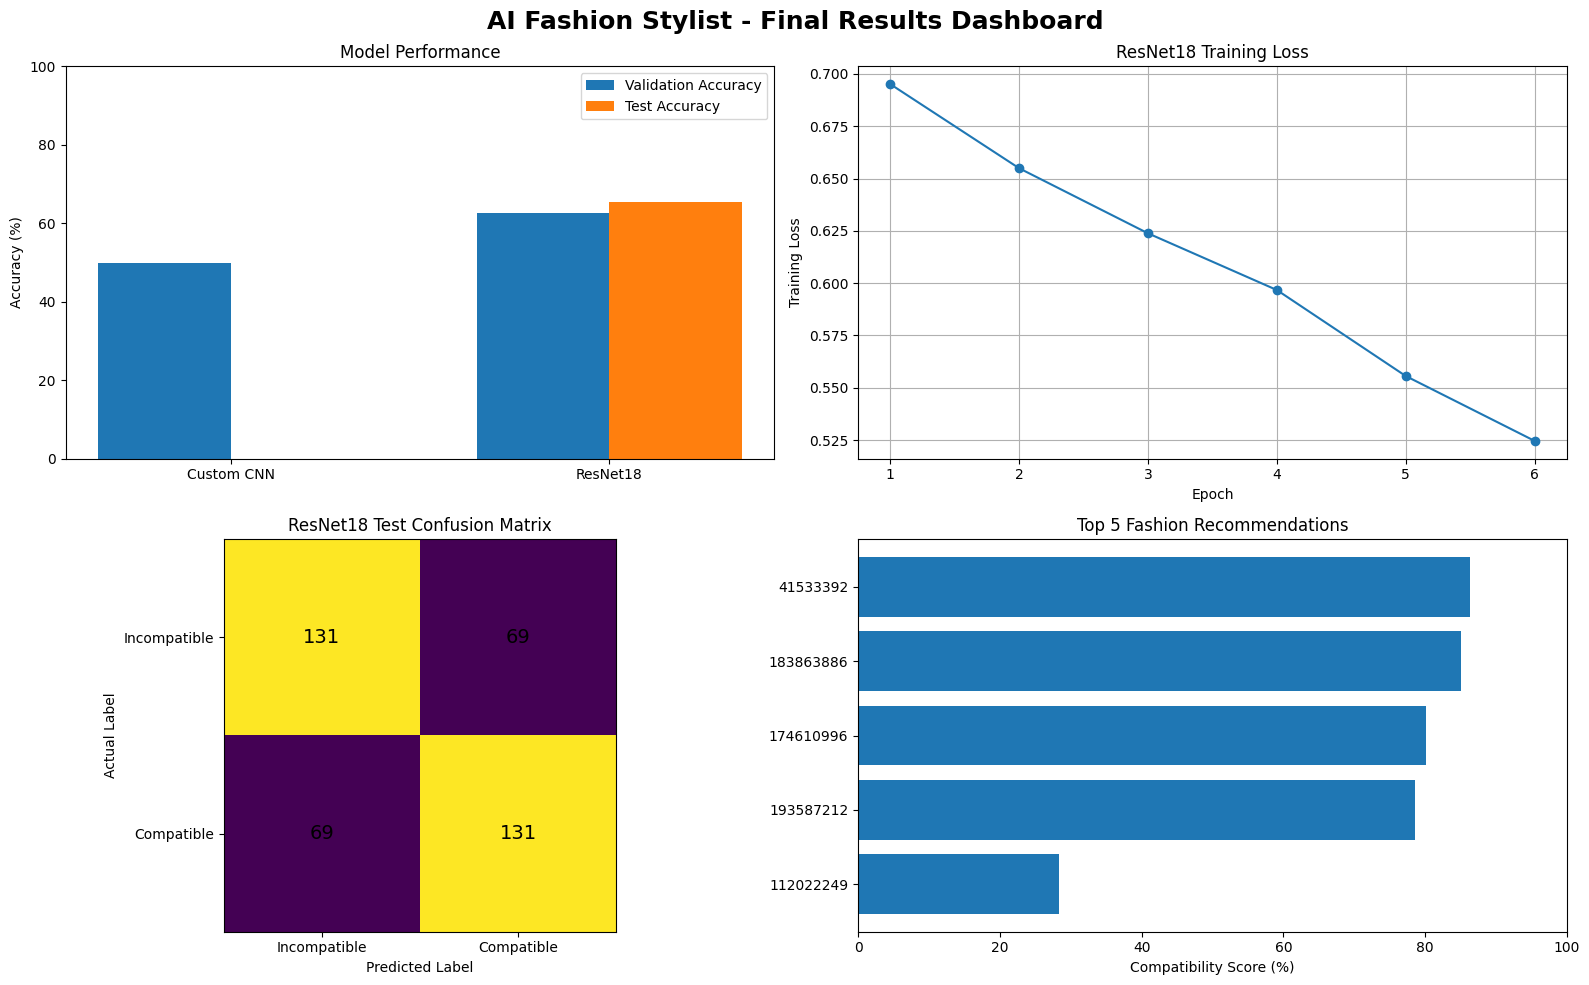

In [ ]:
# Step 3.33.2: Visual AI Fashion Stylist Results Dashboard

import matplotlib.pyplot as plt
import numpy as np

# Create dashboard with 4 charts
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

fig.suptitle(
    "AI Fashion Stylist - Final Results Dashboard",
    fontsize=18,
    fontweight="bold"
)

# --------------------------------------------------
# 1. Model Performance
# --------------------------------------------------
models = ["Custom CNN", "ResNet18"]
validation_accuracy = [50.0, 62.5]
test_accuracy = [0, 65.5]

x = np.arange(len(models))
width = 0.35

axes[0, 0].bar(
    x - width / 2,
    validation_accuracy,
    width,
    label="Validation Accuracy"
)

axes[0, 0].bar(
    x + width / 2,
    test_accuracy,
    width,
    label="Test Accuracy"
)

axes[0, 0].set_title("Model Performance")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(models)
axes[0, 0].set_ylim(0, 100)
axes[0, 0].legend()

# --------------------------------------------------
# 2. Training Loss
# --------------------------------------------------
axes[0, 1].plot(
    training_results["Epoch"],
    training_results["Training Loss"],
    marker="o"
)

axes[0, 1].set_title("ResNet18 Training Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Training Loss")
axes[0, 1].grid(True)

# --------------------------------------------------
# 3. Confusion Matrix
# --------------------------------------------------
cm = np.array(confusion_matrix)

axes[1, 0].imshow(cm)

axes[1, 0].set_title("ResNet18 Test Confusion Matrix")
axes[1, 0].set_xlabel("Predicted Label")
axes[1, 0].set_ylabel("Actual Label")

axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(["Incompatible", "Compatible"])

axes[1, 0].set_yticks([0, 1])
axes[1, 0].set_yticklabels(["Incompatible", "Compatible"])

for row in range(2):
    for column in range(2):
        axes[1, 0].text(
            column,
            row,
            cm[row, column],
            ha="center",
            va="center",
            fontsize=14
        )

# --------------------------------------------------
# 4. Top 5 Recommendations
# --------------------------------------------------
recommendation_results_sorted = recommendation_results.sort_values(
    by="Compatibility Score (%)",
    ascending=True
)

axes[1, 1].barh(
    recommendation_results_sorted["Item ID"],
    recommendation_results_sorted["Compatibility Score (%)"]
)

axes[1, 1].set_title("Top 5 Fashion Recommendations")
axes[1, 1].set_xlabel("Compatibility Score (%)")
axes[1, 1].set_xlim(0, 100)

# --------------------------------------------------
# Display Dashboard
# --------------------------------------------------
plt.tight_layout()
plt.show()

# **Step 3.34.1 — Create the webpage code**

In [ ]:
# Step 3.34.1: Create AI Fashion Stylist Results Webpage

%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="AI Fashion Stylist",
    page_icon="👗",
    layout="wide"
)

# ----------------------------------
# Dashboard Title
# ----------------------------------

st.title("👗 AI Fashion Stylist")

st.write(
    "Deep Learning-Based Outfit Compatibility "
    "and Fashion Recommendation System"
)

st.divider()

# ----------------------------------
# Model Results
# ----------------------------------

st.header("📊 Model Performance")

col1, col2, col3 = st.columns(3)

col1.metric(
    "Custom CNN Validation",
    "50.0%"
)

col2.metric(
    "ResNet18 Validation",
    "62.5%"
)

col3.metric(
    "ResNet18 Test Accuracy",
    "65.5%"
)

# ----------------------------------
# Training Loss
# ----------------------------------

st.header("📉 ResNet18 Training Progress")

epochs = [1, 2, 3, 4, 5, 6]

losses = [
    0.6951,
    0.6549,
    0.6238,
    0.5967,
    0.5556,
    0.5246
]

training_data = pd.DataFrame({
    "Epoch": epochs,
    "Training Loss": losses
})

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    epochs,
    losses,
    marker="o"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("Training Loss Across 6 Epochs")
ax.grid(True)

st.pyplot(fig)

st.dataframe(
    training_data,
    use_container_width=True
)

# ----------------------------------
# Confusion Matrix
# ----------------------------------

st.header("🎯 Test Confusion Matrix")

cm = [
    [131, 69],
    [69, 131]
]

fig, ax = plt.subplots()

ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_xticklabels([
    "Incompatible",
    "Compatible"
])

ax.set_yticks([0, 1])
ax.set_yticklabels([
    "Incompatible",
    "Compatible"
])

ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            cm[i][j],
            ha="center",
            va="center",
            fontsize=14
        )

st.pyplot(fig)

# ----------------------------------
# Recommendations
# ----------------------------------

st.header("👚 Top 5 Fashion Recommendations")

recommendations = pd.DataFrame({
    "Item ID": [
        "41533392",
        "183863886",
        "174610996",
        "193587212",
        "112022249"
    ],

    "Compatibility Score (%)": [
        86.31,
        85.07,
        80.11,
        78.52,
        28.41
    ]
})

st.dataframe(
    recommendations,
    use_container_width=True
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(
    recommendations["Item ID"],
    recommendations["Compatibility Score (%)"]
)

ax.set_xlabel("Compatibility Score (%)")
ax.set_title("Top 5 Recommended Fashion Items")
ax.set_xlim(0, 100)

st.pyplot(fig)

# ----------------------------------
# Best Recommendation
# ----------------------------------

st.success(
    "Best Recommendation: Item 41533392 "
    "| Compatibility Score: 86.31%"
)

st.divider()

st.caption(
    "AI Fashion Stylist | Polyvore Dataset | ResNet18"
)

Writing app.py


# **Step 3.34.2 — Restart the Streamlit webpage**

In [ ]:
# Step 3.34.2: Restart AI Fashion Stylist Webpage

!pkill -f "streamlit run app.py" || true

^C


In [ ]:
# Start the updated Streamlit webpage

!streamlit run app.py --server.port 8501 --server.address 0.0.0.0

/bin/bash: line 1: streamlit: command not found


# **Step 3.34.3 — Fix Port 8501**

In [ ]:
# Step 3.34.3: Stop the old Streamlit server

!fuser -k 8501/tcp

In [ ]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Find the Polyvore images in Colab**

In [ ]:
# Check where the Polyvore images are stored

import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current working directory:
/content

Files and folders:
['.config', 'fashion_stylist_top_recommendations.csv', 'fashion_stylist_resnet18.pth', 'fashion_stylist_recommendations.csv', 'fashion_stylist_final_summary.csv', 'app.py', 'sample_data']


# **Find the fashion images**

In [ ]:
import os

# Search for the recommended Polyvore item images
item_ids = [
    "41533392",
    "183863886",
    "174610996",
    "193587212"
]

search_paths = [
    "/content",
    "/root/.cache/huggingface"
]

for search_path in search_paths:
    print("\nSearching:", search_path)

    if os.path.exists(search_path):
        for root, dirs, files in os.walk(search_path):
            for item_id in item_ids:
                matching_files = [
                    f for f in files
                    if item_id in f
                ]

                for filename in matching_files:
                    print(os.path.join(root, filename))


Searching: /content

Searching: /root/.cache/huggingface


# **Check your recommendation CSV**

In [ ]:
import pandas as pd

# Load your top recommendations
recommendations = pd.read_csv(
    "/content/fashion_stylist_top_recommendations.csv"
)

# Display the recommendation data
print("Recommendation columns:")
print(recommendations.columns.tolist())

print("\nTop recommendations:")
display(recommendations.head())

Recommendation columns:
['Item ID', 'Compatibility Score (%)']

Top recommendations:


,Item ID,Compatibility Score (%)
0,41533392,86.31
1,183863886,85.07
2,174610996,80.11
3,193587212,78.52
4,112022249,28.41


# **Check how the dataset stores images**

In [ ]:
# Check the image information in your Polyvore dataset

print("Dataset type:", type(fashion_train_dataset))

# Inspect the first dataset example
sample = fashion_train_dataset[0]

print("\nSample item ID:")
print(sample[0])

print("\nImage information:")
print(sample[1])

print("\nLabel:")
print(sample[2])

Dataset type: <class '__main__.FashionCompatibilityDataset'>

Sample item ID:
tensor([[[[1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          ...,
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000]],

         [[1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          ...,
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000]],

         [[1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
          [1.0000, 1.0000, 1.0

# **Inspect dataset attributes**

In [ ]:

# Inspect the dataset object without printing the image tensors

print("Dataset attributes:")

for name, value in vars(fashion_train_dataset).items():

    if name.startswith("_"):
        continue

    if hasattr(value, "shape"):
        print(name, "Shape:", value.shape)

    elif isinstance(value, (list, tuple)):
        print(name, "Type:", type(value), "Length:", len(value))

    else:
        print(name, "Type:", type(value))

Dataset attributes:
samples Type: <class 'list'> Length: 3200
image_dataset Shape: (204679, 2)
item_lookup Type: <class 'dict'>
transform Type: <class 'torchvision.transforms.transforms.Compose'>


### **Inspect the image dataset**

In [ ]:

# Inspect one fashion item from the original image dataset

print("Image dataset sample:")
print(fashion_train_dataset.image_dataset[0])

print("\nItem lookup sample:")
print(list(fashion_train_dataset.item_lookup.items())[:5])

Image dataset sample:
{'item_id': '41533392', 'image': {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\x08\x06\x06\x07\x06\x05\x08\x07\x07\x07\t\t\x08\n\x0c\x14\r\x0c\x0b\x0b\x0c\x19\x12\x13\x0f\x14\x1d\x1a\x1f\x1e\x1d\x1a\x1c\x1c $.\' ",#\x1c\x1c(7),01444\x1f\'9=82<.342\xff\xdb\x00C\x01\t\t\t\x0c\x0b\x0c\x18\r\r\x182!\x1c!22222222222222222222222222222222222222222222222222\xff\xc0\x00\x11\x08\x01,\x01,\x03\x01"\x00\x02\x11\x01\x03\x11\x01\xff\xc4\x00\x1f\x00\x00\x01\x05\x01\x01\x01\x01\x01\x01\x00\x00\x00\x00\x00\x00\x00\x00\x01\x02\x03\x04\x05\x06\x07\x08\t\n\x0b\xff\xc4\x00\xb5\x10\x00\x02\x01\x03\x03\x02\x04\x03\x05\x05\x04\x04\x00\x00\x01}\x01\x02\x03\x00\x04\x11\x05\x12!1A\x06\x13Qa\x07"q\x142\x81\x91\xa1\x08#B\xb1\xc1\x15R\xd1\xf0$3br\x82\t\n\x16\x17\x18\x19\x1a%&\'()*456789:CDEFGHIJSTUVWXYZcdefghijstuvwxyz\x83\x84\x85\x86\x87\x88\x89\x8a\x92\x93\x94\x95\x96\x97\x98\x99\x9a\xa2\xa3\xa4\xa5\xa6\xa7\xa8\xa9\xaa\xb2\xb3\xb4\xb5\xb6\x

# **Save your top 5 fashion images**

In [ ]:

# Save the top 5 recommended fashion images

import os
from PIL import Image
from io import BytesIO

# Create folder for recommendation images
image_folder = "/content/recommendation_images"
os.makedirs(image_folder, exist_ok=True)

# Top 5 recommended item IDs
top_item_ids = [
    "41533392",
    "183863886",
    "174610996",
    "193587212",
    "112022249"
]

saved_images = []

for item_id in top_item_ids:

    # Find the image position using the item ID
    image_index = fashion_train_dataset.item_lookup[item_id]

    # Get the original image
    image_record = fashion_train_dataset.image_dataset[image_index]

    # Extract image bytes
    image_bytes = image_record["image"]["bytes"]

    # Open and save the image
    image = Image.open(BytesIO(image_bytes)).convert("RGB")

    image_path = os.path.join(
        image_folder,
        f"{item_id}.jpg"
    )

    image.save(image_path)

    saved_images.append(image_path)

    print("Saved:", image_path)

print("\nTotal images saved:", len(saved_images))


Saved: /content/recommendation_images/41533392.jpg
Saved: /content/recommendation_images/183863886.jpg
Saved: /content/recommendation_images/174610996.jpg
Saved: /content/recommendation_images/193587212.jpg
Saved: /content/recommendation_images/112022249.jpg

Total images saved: 5


# **Download the images to your Mac**

In [ ]:

# Create a ZIP file containing the 5 recommendation images

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/recommendation_images",
    "zip",
    "/content/recommendation_images"
)

print("ZIP file created:", zip_path)

files.download(zip_path)

ZIP file created: /content/recommendation_images.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Check available fashion item metadata

print("Dataset variables containing metadata:")

for name in globals():
    if any(word in name.lower() for word in [
        "metadata",
        "item_info",
        "item_title",
        "item_category"
    ]):
        print(name, type(globals()[name]))

Dataset variables containing metadata:


In [ ]:

# Inspect the fashion dataset structure

print("Dataset columns:")
print(fashion_train_dataset.image_dataset.column_names)

print("\nDataset features:")
print(fashion_train_dataset.image_dataset.features)

print("\nFirst item:")
print({
    "item_id": fashion_train_dataset.image_dataset[0]["item_id"],
    "image_path": fashion_train_dataset.image_dataset[0]["image"]["path"]
})

Dataset columns:
['item_id', 'image']

Dataset features:
{'item_id': Value('string'), 'image': {'bytes': Value('binary'), 'path': Value('string')}}

First item:
{'item_id': '41533392', 'image_path': '41533392.jpg'}


In [ ]:

# Check whether CLIP-related libraries are available

try:
    import transformers
    print("Transformers version:", transformers.__version__)
    print("CLIP library is available.")
except ImportError:
    print("Transformers is not installed.")

Transformers version: 5.21.0
CLIP library is available.


In [ ]:

# Test CLIP on 5 fashion images

import torch
from transformers import CLIPModel, CLIPProcessor
from PIL import Image
from io import BytesIO

# Load pretrained CLIP model
model_name = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(model_name)
clip_processor = CLIPProcessor.from_pretrained(model_name)

# Fashion descriptions to test
fashion_descriptions = [
    "a white shirt",
    "blue denim jeans",
    "black shoes",
    "a fashion handbag",
    "a black blazer"
]

# Test with 5 images
test_item_ids = [
    "41533392",
    "183863886",
    "174610996",
    "193587212",
    "112022249"
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

clip_model = clip_model.to(device)
clip_model.eval()

print("CLIP device:", device)

for item_id in test_item_ids:

    image_index = fashion_train_dataset.item_lookup[item_id]

    image_record = fashion_train_dataset.image_dataset[image_index]

    image_bytes = image_record["image"]["bytes"]

    image = Image.open(
        BytesIO(image_bytes)
    ).convert("RGB")

    inputs = clip_processor(
        text=fashion_descriptions,
        images=[image] * len(fashion_descriptions),
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():

        outputs = clip_model(**inputs)

        scores = outputs.logits_per_image.softmax(dim=1)[0]

    best_index = scores.argmax().item()

    print("\nItem ID:", item_id)
    print("Predicted clothing:", fashion_descriptions[best_index])
    print("CLIP similarity:", round(scores[best_index].item() * 100, 2), "%")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP device: cuda

Item ID: 41533392
Predicted clothing: a black blazer
CLIP similarity: 100.0 %

Item ID: 183863886
Predicted clothing: black shoes
CLIP similarity: 99.22 %

Item ID: 174610996
Predicted clothing: a fashion handbag
CLIP similarity: 36.45 %

Item ID: 193587212
Predicted clothing: black shoes
CLIP similarity: 98.0 %

Item ID: 112022249
Predicted clothing: a fashion handbag
CLIP similarity: 99.74 %


In [ ]:

# Test CLIP with more fashion descriptions

fashion_descriptions = [
    "a white shirt",
    "a black shirt",
    "a blue denim shirt",
    "blue denim jeans",
    "black jeans",
    "white sneakers",
    "black shoes",
    "a fashion handbag",
    "a backpack",
    "a brown leather belt",
    "a black blazer",
    "a dress"
]

test_item_ids = [
    "41533392",
    "183863886",
    "174610996",
    "193587212",
    "112022249"
]

for item_id in test_item_ids:

    image_index = fashion_train_dataset.item_lookup[item_id]

    image_record = fashion_train_dataset.image_dataset[image_index]

    image_bytes = image_record["image"]["bytes"]

    image = Image.open(
        BytesIO(image_bytes)
    ).convert("RGB")

    inputs = clip_processor(
        text=fashion_descriptions,
        images=[image] * len(fashion_descriptions),
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():

        outputs = clip_model(**inputs)

        scores = outputs.logits_per_image[0]

    best_index = scores.argmax().item()

    print("\nItem ID:", item_id)
    print("Predicted clothing:", fashion_descriptions[best_index])
    print("Relative softmax score:",
          round(scores.softmax(dim=0)[best_index].item() * 100, 2),
          "%")



Item ID: 41533392
Predicted clothing: a black blazer
Relative softmax score: 99.89 %

Item ID: 183863886
Predicted clothing: black shoes
Relative softmax score: 93.65 %

Item ID: 174610996
Predicted clothing: a brown leather belt
Relative softmax score: 99.1 %

Item ID: 193587212
Predicted clothing: black shoes
Relative softmax score: 97.76 %

Item ID: 112022249
Predicted clothing: a fashion handbag
Relative softmax score: 61.58 %


In [ ]:

# Test a user fashion request with CLIP

user_request = (
    "I want a white shirt with blue denim. "
    "Recommend matching shoes and accessories."
)

# Fashion item descriptions
fashion_descriptions = [
    "a white shirt",
    "blue denim jeans",
    "black shoes",
    "white sneakers",
    "a fashion handbag",
    "a brown leather belt",
    "a black blazer"
]

# Test the existing 5 images
test_item_ids = [
    "41533392",
    "183863886",
    "174610996",
    "193587212",
    "112022249"
]

print("User request:")
print(user_request)

print("\nFashion item matching:")

for item_id in test_item_ids:

    image_index = fashion_train_dataset.item_lookup[item_id]

    image_record = fashion_train_dataset.image_dataset[image_index]

    image_bytes = image_record["image"]["bytes"]

    image = Image.open(
        BytesIO(image_bytes)
    ).convert("RGB")

    inputs = clip_processor(
        text=fashion_descriptions,
        images=[image] * len(fashion_descriptions),
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():

        outputs = clip_model(**inputs)

        scores = outputs.logits_per_image[0]

    best_index = scores.argmax().item()

    print("\nItem ID:", item_id)
    print("Matched description:",
          fashion_descriptions[best_index])

User request:
I want a white shirt with blue denim. Recommend matching shoes and accessories.

Fashion item matching:

Item ID: 41533392
Matched description: a black blazer

Item ID: 183863886
Matched description: black shoes

Item ID: 174610996
Matched description: a brown leather belt

Item ID: 193587212
Matched description: black shoes

Item ID: 112022249
Matched description: a fashion handbag


In [ ]:

# Check how many fashion images are available

print("Total fashion images:", len(fashion_train_dataset.image_dataset))
print("Total item IDs:", len(fashion_train_dataset.item_lookup))

Total fashion images: 204679
Total item IDs: 204679


In [ ]:

# Prepare 1,000 fashion images for CLIP search

from PIL import Image
from io import BytesIO
import torch

# Select a small dataset sample first
sample_size = 1000

sample_item_ids = list(
    fashion_train_dataset.item_lookup.keys()
)[:sample_size]

print("Images selected for CLIP search:", len(sample_item_ids))
print("First 10 item IDs:", sample_item_ids[:10])

Images selected for CLIP search: 1000
First 10 item IDs: ['41533392', '193587212', '112022249', '174610996', '183863886', '77059550', '194734151', '81028323', '98136117', '114944350']


In [ ]:

# Create CLIP image embeddings (corrected for newer Transformers)

import torch
import torch.nn.functional as F
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm

clip_model.eval()

image_embeddings = []
embedded_item_ids = []

batch_size = 16

for start in tqdm(range(0, len(sample_item_ids), batch_size)):

    batch_ids = sample_item_ids[start:start + batch_size]
    batch_images = []

    for item_id in batch_ids:

        image_index = fashion_train_dataset.item_lookup[item_id]
        image_record = fashion_train_dataset.image_dataset[image_index]

        image_bytes = image_record["image"]["bytes"]

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        batch_images.append(image)

    inputs = clip_processor(
        images=batch_images,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():

        outputs = clip_model.get_image_features(
            pixel_values=inputs["pixel_values"]
        )

        # Extract actual tensor from model output
        if hasattr(outputs, "pooler_output"):
            features = outputs.pooler_output

        elif hasattr(outputs, "image_embeds"):
            features = outputs.image_embeds

        else:
            features = outputs

        # Normalize image features
        features = F.normalize(
            features,
            p=2,
            dim=1
        )

    image_embeddings.extend(features.cpu())
    embedded_item_ids.extend(batch_ids)

# Convert list into tensor
image_embeddings = torch.stack(image_embeddings)

print("Images embedded:", len(embedded_item_ids))
print("Embedding shape:", image_embeddings.shape)
print("Item IDs stored:", len(embedded_item_ids))


  0%|          | 0/63 [00:00<?, ?it/s]

Images embedded: 1000
Embedding shape: torch.Size([1000, 512])
Item IDs stored: 1000


In [ ]:

# Search fashion images using a natural-language prompt

import torch
import torch.nn.functional as F

# User can change this prompt anytime
user_request = "I want to wear a red dress"

# Convert the user's text into CLIP text features
text_inputs = clip_processor(
    text=[user_request],
    return_tensors="pt",
    padding=True,
    truncation=True
).to(device)

clip_model.eval()

with torch.no_grad():

    text_outputs = clip_model.get_text_features(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs.get("attention_mask")
    )

    # Extract tensor from model output
    if hasattr(text_outputs, "pooler_output"):
        text_features = text_outputs.pooler_output

    elif hasattr(text_outputs, "text_embeds"):
        text_features = text_outputs.text_embeds

    else:
        text_features = text_outputs

    text_features = F.normalize(
        text_features,
        p=2,
        dim=1
    )

# Compare the text with all 1,000 image embeddings
similarities = image_embeddings @ text_features.cpu().T

# Find the 5 most similar images
top_k = 5

top_scores, top_indices = torch.topk(
    similarities.squeeze(),
    k=top_k
)

print("User request:", user_request)
print("\nTop matching fashion images:")

for rank, (score, index) in enumerate(
    zip(top_scores, top_indices), start=1
):

    item_id = embedded_item_ids[index.item()]

    print(
        f"{rank}. Item ID: {item_id} | "
        f"Similarity: {score.item():.4f}"
    )


User request: I want to wear a red dress

Top matching fashion images:
1. Item ID: 204381399 | Similarity: 0.2967
2. Item ID: 126843285 | Similarity: 0.2935
3. Item ID: 209642555 | Similarity: 0.2808
4. Item ID: 185151351 | Similarity: 0.2783
5. Item ID: 205562596 | Similarity: 0.2734


In [127]:

# Dynamic Fashion Search
# User can enter ANY fashion request

user_request = input("What outfit do you want? ")

# Convert user request into CLIP text embeddings
text_inputs = clip_processor(
    text=[user_request],
    return_tensors="pt",
    padding=True,
    truncation=True
).to(device)

clip_model.eval()

with torch.no_grad():

    text_outputs = clip_model.get_text_features(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs.get("attention_mask")
    )

    if hasattr(text_outputs, "pooler_output"):
        text_features = text_outputs.pooler_output

    elif hasattr(text_outputs, "text_embeds"):
        text_features = text_outputs.text_embeds

    else:
        text_features = text_outputs

    text_features = F.normalize(
        text_features,
        p=2,
        dim=1
    )

# Search all stored image embeddings
similarities = image_embeddings @ text_features.cpu().T

# Retrieve top 5 matching images
top_k = 5

top_scores, top_indices = torch.topk(
    similarities.squeeze(),
    k=top_k
)

print("\nYour fashion request:", user_request)
print("\nRecommended fashion items:")

for rank, (score, index) in enumerate(
    zip(top_scores, top_indices),
    start=1
):

    item_id = embedded_item_ids[index.item()]

    print(
        f"{rank}. Item ID: {item_id} | "
        f"Similarity: {score.item():.4f}"
    )


What outfit do you want? red

Your fashion request: red

Recommended fashion items:
1. Item ID: 202149363 | Similarity: 0.2802
2. Item ID: 126843285 | Similarity: 0.2614
3. Item ID: 21937082 | Similarity: 0.2604
4. Item ID: 204381399 | Similarity: 0.2604
5. Item ID: 205562596 | Similarity: 0.2580


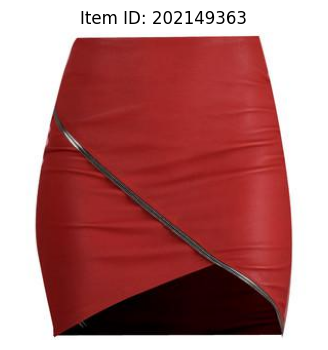

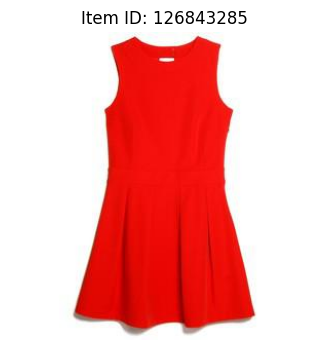

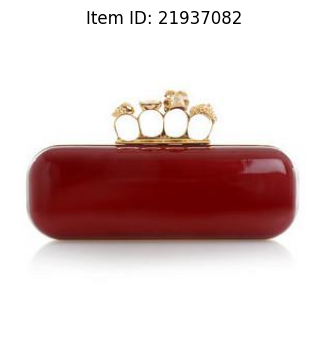

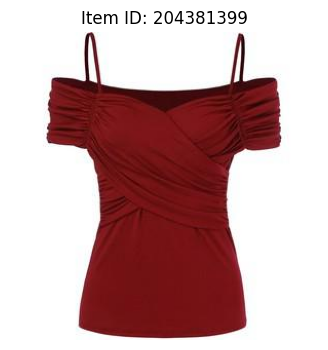

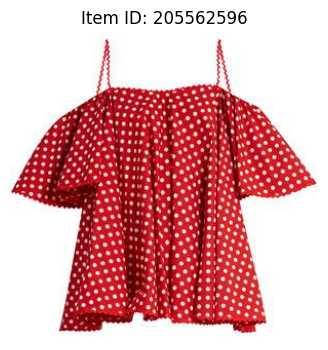

In [128]:

# Display the 5 fashion images found by CLIP

import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

for index in top_indices:

    item_id = embedded_item_ids[index.item()]

    image_index = fashion_train_dataset.item_lookup[item_id]

    image_record = fashion_train_dataset.image_dataset[image_index]

    image_bytes = image_record["image"]["bytes"]

    image = Image.open(
        BytesIO(image_bytes)
    ).convert("RGB")

    plt.figure(figsize=(4, 4))

    plt.imshow(image)

    plt.title(f"Item ID: {item_id}")

    plt.axis("off")

    plt.show()


In [129]:

# Save CLIP image embeddings

import torch

torch.save(
    {
        "image_embeddings": image_embeddings,
        "item_ids": embedded_item_ids
    },
    "fashion_clip_embeddings.pt"
)

print("CLIP embeddings saved successfully!")
print("Total images:", len(embedded_item_ids))


CLIP embeddings saved successfully!
Total images: 1000


In [130]:

# Test different clothing categories

fashion_categories = [
    "a dress",
    "a shirt",
    "a pair of jeans",
    "a pair of shoes",
    "a handbag",
    "a scarf",
    "a pair of earrings"
]

print("Fashion categories available for testing:")

for category in fashion_categories:
    print("-", category)


Fashion categories available for testing:
- a dress
- a shirt
- a pair of jeans
- a pair of shoes
- a handbag
- a scarf
- a pair of earrings


In [131]:

# Identify clothing categories using CLIP

import torch
import torch.nn.functional as F

# Category descriptions
fashion_categories = [
    "a dress",
    "a shirt",
    "a pair of jeans",
    "a pair of shoes",
    "a handbag",
    "a scarf",
    "a pair of earrings"
]

clip_model.eval()

# Convert categories into CLIP text embeddings
text_inputs = clip_processor(
    text=fashion_categories,
    return_tensors="pt",
    padding=True,
    truncation=True
).to(device)

with torch.no_grad():

    text_outputs = clip_model.get_text_features(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs.get("attention_mask")
    )

    if hasattr(text_outputs, "pooler_output"):
        category_embeddings = text_outputs.pooler_output

    elif hasattr(text_outputs, "text_embeds"):
        category_embeddings = text_outputs.text_embeds

    else:
        category_embeddings = text_outputs

    category_embeddings = F.normalize(
        category_embeddings,
        p=2,
        dim=1
    )

# Compare every image with all clothing categories
category_scores = (
    image_embeddings @ category_embeddings.cpu().T
)

# Assign the best matching category to each image
category_indices = category_scores.argmax(dim=1)

image_categories = [
    fashion_categories[index.item()]
    for index in category_indices
]

print("Category identification completed!")
print("Total images classified:", len(image_categories))

print("\nFirst 10 image categories:")

for item_id, category in zip(
    embedded_item_ids[:10],
    image_categories[:10]
):
    print(item_id, "->", category)


Category identification completed!
Total images classified: 1000

First 10 image categories:
41533392 -> a shirt
193587212 -> a pair of shoes
112022249 -> a pair of earrings
174610996 -> a scarf
183863886 -> a pair of shoes
77059550 -> a pair of shoes
194734151 -> a dress
81028323 -> a handbag
98136117 -> a handbag
114944350 -> a pair of shoes


In [132]:

# Save existing fashion search results for Streamlit

import torch
import pandas as pd

# Create a table containing each item's ID and category
fashion_results = pd.DataFrame({
    "item_id": embedded_item_ids,
    "category": image_categories
})

# Save category information
fashion_results.to_csv(
    "fashion_categories.csv",
    index=False
)

# Save embeddings and their matching item IDs
torch.save(
    {
        "image_embeddings": image_embeddings,
        "item_ids": embedded_item_ids,
        "categories": image_categories
    },
    "fashion_clip_embeddings.pt"
)

print("Fashion data saved successfully!")
print("Total images:", len(fashion_results))
print("\nCategory counts:")
print(fashion_results["category"].value_counts())


Fashion data saved successfully!
Total images: 1000

Category counts:
category
a pair of shoes       209
a handbag             205
a shirt               168
a pair of earrings    165
a dress               138
a pair of jeans        62
a scarf                53
Name: count, dtype: int64


In [133]:

# KK84
# Prepare the 1,000 fashion images for Streamlit

import os
import zipfile
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm

zip_filename = "fashion_images_1000.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for item_id in tqdm(embedded_item_ids):

        image_index = fashion_train_dataset.item_lookup[item_id]

        image_record = fashion_train_dataset.image_dataset[image_index]

        image_bytes = image_record["image"]["bytes"]

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        image_buffer = BytesIO()

        image.save(
            image_buffer,
            format="JPEG"
        )

        zip_file.writestr(
            f"images/{item_id}.jpg",
            image_buffer.getvalue()
        )

print("Fashion images ZIP created!")
print("Total images:", len(embedded_item_ids))
print("File:", zip_filename)


  0%|          | 0/1000 [00:00<?, ?it/s]

Fashion images ZIP created!
Total images: 1000
File: fashion_images_1000.zip


In [134]:
from google.colab import files

files.download("fashion_images_1000.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [135]:
from google.colab import files
import zipfile

with zipfile.ZipFile("fashion_search_data.zip", "w") as z:
    z.write("fashion_categories.csv")
    z.write("fashion_clip_embeddings.pt")

files.download("fashion_search_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [136]:
import os

for root, dirs, files_list in os.walk("/content"):
    for file in files_list:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

/content/fashion_stylist_resnet18.pth


In [137]:
from google.colab import files

files.download("/content/fashion_stylist_resnet18.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>